# Step 23 — Pick-index and source-group diagnostics

Run after steps 20–22. All step-specific computation and plotting functions are defined in this notebook; shared utility and comparison helpers remain imported. It reads existing pick indexes and writes figures, optional summary CSVs and heuristic QC flags to the configured external diagnostics directory. It does not change picks or perform waveform/event association.

The individual, monthly and merged tables overlap: totals across all sources double-count much of the same material. Compare the sources separately; do not sum their counts as an earthquake catalogue. UTC plot labels describe parser representation only; independent clock offsets and drift remain unresolved.

## 1. Review configuration

Set `CONFIG_FILE` if needed and inspect input/output paths and tolerances. This setup cell does not execute the workflow.

In [10]:
from pathlib import Path
import sys
from IPython.display import display

# Find the adjacent local package whether Jupyter starts here or in the project root.
_candidates = [Path.cwd(), Path.cwd() / '10_conversion', *Path.cwd().parents]
PIPELINE_DIR = next((p for p in _candidates if (p / 'pinatubo_steps').is_dir()), None)
if PIPELINE_DIR is None:
    raise FileNotFoundError('Open this notebook from the pipeline folder or project root.')
if str(PIPELINE_DIR) not in sys.path:
    sys.path.insert(0, str(PIPELINE_DIR))
from pinatubo_steps.config import pipeline_paths

CONFIG_FILE = None  # Default: conversion_config.json; or set an explicit JSON path.
P = pipeline_paths(config_file=CONFIG_FILE)
DATA_TOP = Path(P['DATA_TOP'])
print('Configuration:', P['CONFIG_FILE'])
print('External outputs:', P['OUTPUT_ROOT'])

SETTINGS = dict(
    individual=P['INDIV_PICK_INDEX'],
    monthly=P['MONTHLY_PICK_INDEX'],
    merged=P['MERGED_PICK_INDEX'],
    outdir=P['STEP23_DIR'],
    top_stations=int(P['MAX_STATION_COUNT']),
    ps_delay_max=float(P['MAX_PS_DELAY']),
    emit_csv=True,
    emit_qc=True,
)
display(SETTINGS)

Configuration: /Users/thompsong/Developer/Pinatubo1991SeismicData/10_conversion/conversion_config.json
External outputs: /Users/thompsong/work/Pinatubo1991Processing/converted


{'individual': '/Users/thompsong/work/Pinatubo1991Processing/converted/pipeline_tmp/20_individual_pick_index.csv',
 'monthly': '/Users/thompsong/work/Pinatubo1991Processing/converted/pipeline_tmp/21_monthly_pick_index.csv',
 'merged': '/Users/thompsong/work/Pinatubo1991Processing/converted/pipeline_tmp/22_merged_pick_index.csv',
 'outdir': '/Users/thompsong/work/Pinatubo1991Processing/converted/pipeline_tmp/qc/step23_pick_event_diagnostics',
 'top_stations': 20,
 'ps_delay_max': 15.0,
 'emit_csv': True,
 'emit_qc': True}

## 2. Imports, table loading and summaries

At least `event_id` and `pick_time` are required. Missing descriptive columns are added. Unparseable times are excluded from plots; the current implementation does not emit a rejected-row audit. Phase labels are uppercased, with missing labels assigned UNK.

An “event” here means a `(source, event_id)` group. Its date is the earliest pick date, and its “duration” is the last-minus-first pick time, not signal duration. Pick counts use each pick's own date, so groups crossing midnight can contribute picks to two days. Daily summaries contain observed days only; missing dates are not explicit zero counts, and lines/areas can bridge gaps.

P–S calculations pair the earliest P and earliest S within each source/group/station, without requiring identical channel or location. All computed pairs and their validity flags are exported when CSV output is enabled; delay plots use only values between zero and `ps_delay_max` inclusive.

In [11]:
from __future__ import annotations

import json

from pathlib import Path

from typing import Dict, List, Optional, Tuple

import numpy as np

import pandas as pd

import matplotlib.pyplot as plt

from pinatubo_steps.shared import (to_dt, ensure_cols, savefig)

REQUIRED_COLS = {"event_id", "pick_time"}

def safe_read_csv(path: Optional[str]) -> Optional[pd.DataFrame]:
    if not path:
        return None
    p = Path(path)
    if not p.exists():
        raise FileNotFoundError(f"Missing input CSV: {p}")
    return pd.read_csv(p)

def normalize_phase(series: pd.Series) -> pd.Series:
    s = series.astype("string").fillna("").str.strip().str.upper()
    # Keep common canonical labels; map blanks/unknowns to "UNK"
    s = s.replace({"": "UNK", "NONE": "UNK", "NAN": "UNK"})
    return s

def day_floor_utc(ts: pd.Series) -> pd.Series:
    # pandas UTC timestamps → daily bins
    return ts.dt.floor("D")

def load_pick_table(path: str, source: str) -> pd.DataFrame:
    df = pd.read_csv(path, low_memory=False)
    missing = REQUIRED_COLS - set(df.columns)
    if missing:
        raise ValueError(f"{source} CSV missing required columns: {sorted(missing)}")

    df = ensure_cols(df, ["station", "channel", "seed_id", "phase", "pick_id"])
    df = df.copy()
    df["pick_time"] = to_dt(df["pick_time"])

    bad = df["pick_time"].isna()
    if bad.any():
        # Keep a clean table for plotting; caller can QC counts from this
        df = df.loc[~bad].reset_index(drop=True)

    df["source"] = source
    df["phase"] = normalize_phase(df["phase"])
    df["date"] = day_floor_utc(df["pick_time"])
    return df

def compute_daily_pick_counts(df: pd.DataFrame) -> pd.DataFrame:
    out = (
        df.groupby(["date", "source"], as_index=False)
        .size()
        .rename(columns={"size": "n_picks"})
        .sort_values(["date", "source"])
    )
    return out

def compute_event_table(df: pd.DataFrame) -> pd.DataFrame:
    """
    Build event-level table from pick table:
    - event_time = min pick_time in event
    - duration_s = max-min
    - n_picks
    """
    g = df.groupby(["source", "event_id"], as_index=False)
    ev = g.agg(
        event_time=("pick_time", "min"),
        end_time=("pick_time", "max"),
        n_picks=("pick_time", "size"),
    )
    ev["duration_s"] = (ev["end_time"] - ev["event_time"]).dt.total_seconds()
    ev["date"] = day_floor_utc(ev["event_time"])
    return ev.sort_values(["source", "event_time", "event_id"]).reset_index(drop=True)

def compute_daily_event_counts(ev: pd.DataFrame) -> pd.DataFrame:
    out = (
        ev.groupby(["date", "source"], as_index=False)
        .size()
        .rename(columns={"size": "n_events"})
        .sort_values(["date", "source"])
    )
    return out

def compute_event_size_stats(ev: pd.DataFrame) -> pd.DataFrame:
    def q(x, p):
        return float(np.nanquantile(x, p)) if len(x) else np.nan

    rows = []
    for (date, source), sub in ev.groupby(["date", "source"]):
        x = sub["n_picks"].astype(float).to_numpy()
        rows.append(
            {
                "date": date,
                "source": source,
                "median_picks": float(np.nanmedian(x)) if len(x) else np.nan,
                "p10": q(x, 0.10),
                "p90": q(x, 0.90),
                "max": float(np.nanmax(x)) if len(x) else np.nan,
            }
        )
    return pd.DataFrame(rows).sort_values(["date", "source"])

def compute_station_pick_rates(df: pd.DataFrame) -> pd.DataFrame:
    out = (
        df.groupby(["date", "source", "station"], as_index=False)
        .size()
        .rename(columns={"size": "n_picks"})
        .sort_values(["date", "source", "station"])
    )
    return out

def compute_phase_counts(df: pd.DataFrame) -> pd.DataFrame:
    out = (
        df.groupby(["date", "source", "phase"], as_index=False)
        .size()
        .rename(columns={"size": "n_picks"})
        .sort_values(["date", "source", "phase"])
    )
    return out

def compute_ps_delays(
    df: pd.DataFrame,
    ps_delay_max: float = 60.0,
) -> pd.DataFrame:
    """
    Compute P-S delay (seconds) within each (source,event_id,station),
    using earliest P and earliest S for that station/event.

    Returns rows with:
    - source, event_id, station, p_time, s_time, ps_delay_s
    """
    needed = df[["source", "event_id", "station", "phase", "pick_time"]].copy()
    needed["station"] = needed["station"].astype("string").fillna("").str.strip()
    needed = needed[needed["station"].ne("")].copy()

    # Keep only P and S
    needed = needed[needed["phase"].isin(["P", "S"])].copy()
    if needed.empty:
        return needed.assign(ps_delay_s=pd.Series(dtype=float))

    # Earliest P/S per group
    pmin = (
        needed[needed["phase"] == "P"]
        .groupby(["source", "event_id", "station"], as_index=False)["pick_time"]
        .min()
        .rename(columns={"pick_time": "p_time"})
    )
    smin = (
        needed[needed["phase"] == "S"]
        .groupby(["source", "event_id", "station"], as_index=False)["pick_time"]
        .min()
        .rename(columns={"pick_time": "s_time"})
    )

    merged = pmin.merge(smin, on=["source", "event_id", "station"], how="inner")
    merged["ps_delay_s"] = (merged["s_time"] - merged["p_time"]).dt.total_seconds()

    # Keep reasonable range (still export full, but plotting uses filtered)
    merged["ps_delay_s"] = merged["ps_delay_s"].astype(float)
    merged["ps_delay_ok"] = merged["ps_delay_s"].between(0.0, ps_delay_max, inclusive="both")
    return merged

## Reading the P–S delay diagnostics

### Purpose: check pick parsing and source grouping before waveform association

Here “P–S delay” means **S arrival time minus P arrival time**, `t_S − t_P`, in seconds. It is an arrival-time difference, not an absolute clock offset or waveform duration. These plots are intended to reveal suspicious phase parsing, minute/date rollover handling, source grouping, or unmatched picks before those records enter later associations. Negative or unusually large differences identify records to inspect; they do not by themselves identify the cause or prove that the picks are wrong. A real change in source position, phase identification or picking practice can also change the distribution.

### How one delay is calculated

1. Read the individual, monthly and merged CSVs separately. Parse pick times and normalize phase labels to uppercase. Only the exact phase labels `P` and `S` enter this calculation; other labels are not inferred to be P or S.
2. Group by **input source, event_id and station**. Take the earliest P and earliest S in each group. For example, P at 12:00:03.2 and S at 12:00:05.7 yield a delay of 2.5 seconds.
3. Retain only groups with both phases and a nonblank station. Multiple picks are reduced to one pair, so the pair count is not the total number of picks. Pairing is by station, not full SEED ID: P and S may come from different components, locations or gain channels. Source group IDs may also be imperfect. These assumptions deserve inspection when interpreting an unusual pair.
4. Calculate `ps_delay_s = s_time - p_time` and flag `ps_delay_ok` when **0 ≤ delay ≤ SETTINGS['ps_delay_max']**. The default is 60 seconds; inspect the configured value above. This is a screening bound, not a model-derived travel-time limit.
5. Export all computed pairs, including out-of-range values, to `23_ps_delay_distribution.csv` when `emit_csv=True`. Rows include source, event ID, station, P/S times, delay and screening flag. Groups missing either phase do not appear in this table. Plots use only pairs passing the bound.

### What the three station boxplots show

There is one station boxplot for each input table, when that table has accepted P–S pairs:

| Figure | Records used | Why examine it? |
|---|---|---|
| `23_box_ps_delay_by_station_individual.png` | P/S pairs within individual-file groups from step 20. | Establish a comparison from the preferred individual-file picks; check station-specific spreads and unusual groupings. “Preferred” does not mean independently validated. |
| `23_box_ps_delay_by_station_monthly.png` | P/S pairs within monthly-file blocks from step 21. | Check whether block parsing or time reconstruction produces station patterns that differ from the individual-file records. Coverage and event populations can differ, so a distribution difference alone is not a parser failure. |
| `23_box_ps_delay_by_station_merged.png` | P/S pairs recalculated within the surviving groups in step 22. | Inspect the result after duplicate suppression. This is not a new independent sample: it overlaps the two inputs. Some P/S pairs can disappear if one phase was suppressed but the remaining pick keeps its original source-group ID. |

**Axes and box meaning:** the horizontal axis lists stations; the vertical axis is S−P in seconds. The line is the median, the box spans the 25th–75th percentiles, and whiskers extend to the most distant observations within 1.5 interquartile ranges of the box. Points beyond the whiskers are hidden (`showfliers=False`), not removed from the exported pair table. They have already passed the separate 0–maximum screening bound. A narrow box means limited spread among the accepted pairs; it does not establish accurate absolute timing or correct phase assignment.

Stations are selected using the largest accepted-pair counts **across all input tables**, up to `top_stations`. Because the merged table overlaps the inputs, that ranking is a display choice rather than an independent network statistic. Each source plot omits selected stations without accepted pairs; plots may therefore have different station sets. There is no time axis: these are distributions pooled over each input table's full date range, not P–S delay time series. If a source has no accepted pairs, its boxplot is not generated.

### The additional P–S histogram

`23_hist_ps_delay_s.png` overlays accepted delay distributions for individual, monthly and merged tables, pooling stations. The vertical axis is the number of pairs per bin, not probability or rate. The current implementation chooses 80 bins separately for each source; bin edges need not match, so use this for a broad visual check rather than exact source-by-source bin comparisons. Different sample sizes and date/station coverage influence the shapes. The input populations overlap and their counts must not be added. If pairs exist but all fail the bound, the plot instead reports that none passed.

### QC flags and follow-up

The QC JSON reports, separately for each source, the fraction of **all paired records** outside the configured delay bounds and flags a fraction greater than 2%. This heuristic is a prompt to inspect rows, not a rejection rule. Missing P/S counterparts are outside that denominator, and the station boxplots hide both screened-out pairs and whisker outlier points; an apparently tidy plot can therefore coexist with important problems.

For a suspicious station or source, open `23_ps_delay_distribution.csv`, select its `ps_delay_ok=False` rows (and any unusual accepted delays), and trace the event ID/station back to the relevant step-20/21/22 table. Inspect `raw_line`, `raw_lineno` and `pha_file` to distinguish phase parsing, minute rollover, source-block membership and inherited legacy errors. Compare the same records across sources using the independent cross-check at the end of this notebook; matching source distributions alone does not validate individual pairs.

An additive clock offset common to the P and S timestamps cancels in S−P. Thus these plots cannot establish alignment with MDETECT, RSAM, SSAM or helicorder clocks. Drift over the P-to-S interval, clock discontinuities, mixed timing sources and incorrectly paired phases can still affect a delay. Do not infer hypocentral distance without an appropriate velocity model and a justified P/S association.


## 3. Plotting functions

The existing plot styles are preserved in this consolidation: source-comparison time series, distributions, per-source station stacked areas, phase fractions and P–S boxplots. These diagnose source grouping and picking coverage, not continuous instrument uptime. “Top stations” are selected globally across the overlapping input sources. Phase fractions combine labels outside P/S/UNK into OTHER. Boxplots hide individual outlier points without deleting their exported records.

The events-per-day figure uses separate, shared-scale panels for individual, monthly and merged tables. Daily bars have one-day width and include zero-count calendar days. Within each panel, bars stack individual-file versus monthly-file group origins where available. The panels must not be stacked together because the input tables overlap. Counts remain source-group counts, not confirmed earthquakes. Other plot styles are unchanged.


In [12]:
def plot_daily_group_bars(df: pd.DataFrame, outpath: Path) -> None:
    """Stack source-group origins within each table; never sum overlapping tables."""
    import matplotlib.dates as mdates
    work = df.copy()
    if 'event_id_source' not in work:
        work['event_id_source'] = 'unspecified'
    work['group_origin'] = work['event_id_source'].fillna('unspecified').replace({
        'individual_pha_filename': 'Individual-file group',
        'monthly_phase_block': 'Monthly-file group',
    })
    groups = work.groupby(['source', 'event_id'], as_index=False).agg(
        event_time=('pick_time', 'min'), group_origin=('group_origin', 'first'))
    groups['date'] = groups['event_time'].dt.floor('D')
    days = pd.date_range(groups['date'].min(), groups['date'].max(), freq='D')
    sources = [s for s in ['individual', 'monthly', 'merged'] if s in set(groups['source'])]
    sources += sorted(set(groups['source']) - set(sources))
    origins = sorted(groups['group_origin'].unique())
    colors = {origin: plt.get_cmap('tab10')(i % 10) for i, origin in enumerate(origins)}
    fig, axes = plt.subplots(len(sources), 1, sharex=True, sharey=True,
                             figsize=(12, 2.8 * len(sources)), squeeze=False)
    for ax, source in zip(axes[:, 0], sources):
        counts = (groups[groups['source'].eq(source)]
                  .groupby(['date', 'group_origin']).size().unstack(fill_value=0)
                  .reindex(index=days, columns=origins, fill_value=0))
        bottom = np.zeros(len(days))
        for origin in origins:
            values = counts[origin].to_numpy()
            if values.sum():
                ax.bar(days, values, bottom=bottom, width=1.0, align='edge',
                       linewidth=0, color=colors[origin], label=origin)
            bottom += values
        ax.set_title(source.capitalize(), loc='left')
        ax.set_ylabel('Source groups/day')
        ax.set_ylim(bottom=0)
        ax.yaxis.get_major_locator().set_params(integer=True)
        ax.grid(axis='y', alpha=0.2)
        ax.set_axisbelow(True)
        ax.legend(loc='upper right', fontsize=8)
    peak = groups.groupby(['source', 'date']).size().max()
    axes[0, 0].set_ylim(0, max(1, peak * 1.08))
    locator = mdates.AutoDateLocator(minticks=5, maxticks=12)
    axes[-1, 0].xaxis.set_major_locator(locator)
    axes[-1, 0].xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
    axes[-1, 0].set_xlim(days[0], days[-1] + pd.Timedelta(days=1))
    axes[-1, 0].set_xlabel('Recorded earliest-pick date (clock offsets not independently verified)')
    fig.suptitle('Pick groups per day — input tables overlap; compare panels separately')
    savefig(outpath)

def plot_timeseries_multi(daily: pd.DataFrame, value_col: str, title: str, outpath: Path) -> None:
    plt.figure(figsize=(11, 4))
    for source, sub in daily.groupby("source"):
        plt.plot(sub["date"], sub[value_col], marker="o", linewidth=1, markersize=2, label=source)
    plt.title(title)
    plt.xlabel("Date (UTC)")
    plt.ylabel(value_col)
    plt.grid(True, alpha=0.3)
    plt.legend()
    savefig(outpath)

def plot_timeseries_stat(ev: pd.DataFrame, stat_col: str, title: str, outpath: Path) -> None:
    # ev here is per-event; aggregate per-day per-source
    agg = (
        ev.groupby(["date", "source"], as_index=False)[stat_col]
        .median()
        .rename(columns={stat_col: f"median_{stat_col}"})
        .sort_values(["date", "source"])
    )
    plt.figure(figsize=(11, 4))
    for source, sub in agg.groupby("source"):
        plt.plot(sub["date"], sub[f"median_{stat_col}"], marker="o", linewidth=1, markersize=2, label=source)
    plt.title(title)
    plt.xlabel("Date (UTC)")
    plt.ylabel(f"median_{stat_col}")
    plt.grid(True, alpha=0.3)
    plt.legend()
    savefig(outpath)

def plot_hist_by_source(ev_or_df: pd.DataFrame, col: str, title: str, outpath: Path, bins: int = 60) -> None:
    plt.figure(figsize=(9, 4))
    for source, sub in ev_or_df.groupby("source"):
        x = sub[col].dropna().astype(float).to_numpy()
        if len(x) == 0:
            continue
        plt.hist(x, bins=bins, alpha=0.4, label=source)
    plt.title(title)
    plt.xlabel(col)
    plt.ylabel("count")
    plt.grid(True, alpha=0.3)
    plt.legend()
    savefig(outpath)

def plot_station_stacked_area(
    station_rates: pd.DataFrame,
    top_stations: int,
    outpath: Path,
    title: str,
) -> None:
    # Choose global top stations by total picks
    totals = (
        station_rates.groupby("station", as_index=False)["n_picks"].sum()
        .sort_values("n_picks", ascending=False)
    )
    keep = totals["station"].head(top_stations).tolist()

    df = station_rates[station_rates["station"].isin(keep)].copy()
    if df.empty:
        return

    # Plot per source separately (stacked area gets messy across sources)
    for source, sub in df.groupby("source"):
        pivot = (
            sub.pivot_table(index="date", columns="station", values="n_picks", aggfunc="sum", fill_value=0)
            .sort_index()
        )
        plt.figure(figsize=(11, 4))
        plt.stackplot(pivot.index, pivot.T.values, labels=pivot.columns)
        plt.title(f"{title} — {source} (top {top_stations})")
        plt.xlabel("Date (UTC)")
        plt.ylabel("n_picks")
        plt.grid(True, alpha=0.3)
        plt.legend(loc="upper left", ncol=2, fontsize=8)
        savefig(outpath.parent / f"{outpath.stem}_{source}{outpath.suffix}")

def plot_phase_fraction(
    phase_counts: pd.DataFrame,
    outpath: Path,
    title: str,
    phases: Optional[List[str]] = None,
) -> None:
    if phases is None:
        phases = ["P", "S", "UNK"]

    # Ensure all phases present
    df = phase_counts.copy()
    df["phase"] = df["phase"].astype("string").fillna("UNK")
    df.loc[~df["phase"].isin(phases), "phase"] = "OTHER"

    for source, sub in df.groupby("source"):
        pivot = (
            sub.pivot_table(index="date", columns="phase", values="n_picks", aggfunc="sum", fill_value=0)
            .sort_index()
        )

        # Convert to fractions
        tot = pivot.sum(axis=1).replace(0, np.nan)
        frac = pivot.div(tot, axis=0).fillna(0.0)

        # Plot stacked
        plt.figure(figsize=(11, 4))
        cols = [c for c in ["P", "S", "UNK", "OTHER"] if c in frac.columns]
        plt.stackplot(frac.index, frac[cols].T.values, labels=cols)
        plt.title(f"{title} — {source}")
        plt.xlabel("Date (UTC)")
        plt.ylabel("fraction")
        plt.ylim(0, 1)
        plt.grid(True, alpha=0.3)
        plt.legend(loc="upper left", ncol=4, fontsize=9)
        savefig(outpath.parent / f"{outpath.stem}_{source}{outpath.suffix}")

def plot_ps_delay_box_by_station(ps: pd.DataFrame, top_stations: int, outpath: Path, title: str) -> None:
    if ps.empty:
        return

    # Restrict to OK delays only for the boxplot
    ps_ok = ps[ps["ps_delay_ok"]].copy()
    if ps_ok.empty:
        return

    # Global top stations by number of P-S pairs
    st = (
        ps_ok.groupby("station", as_index=False)
        .size()
        .rename(columns={"size": "n_pairs"})
        .sort_values("n_pairs", ascending=False)
    )
    keep = st["station"].head(top_stations).tolist()

    for source, sub in ps_ok[ps_ok["station"].isin(keep)].groupby("source"):
        data = []
        labels = []
        for station in keep:
            vals = sub.loc[sub["station"] == station, "ps_delay_s"].dropna().astype(float).to_numpy()
            if len(vals) == 0:
                continue
            data.append(vals)
            labels.append(station)

        if not data:
            continue

        plt.figure(figsize=(11, 4))
        plt.boxplot(data, tick_labels=labels, showfliers=False)
        plt.title(f"{title} — {source} (top {top_stations} stations)")
        plt.xlabel("Station")
        plt.ylabel("P–S delay (s)")
        plt.grid(True, alpha=0.3)
        savefig(outpath.parent / f"{outpath.stem}_{source}{outpath.suffix}")

## 4. QC flags and workflow

QC flags are prompts for inspection, not automatic rejection: P–S outlier fraction >2%, any daily median group span >120 s, and >25% of P-picked stations lacking S picks. The legacy zero-event-day flag only examines observed days; a false value does not demonstrate complete coverage.

The run cell creates the output directory and overwrites products with matching names. Products from older runs are not cleaned automatically; the preview may include older PNGs. CSV output includes daily picks/groups, group-size statistics, station rates, phase counts, available P–S pairs and group tables. QC JSON is controlled by `emit_qc`.

In [13]:
def build_qc_flags(
    df_all: pd.DataFrame,
    ev_all: pd.DataFrame,
    ps: pd.DataFrame,
    ps_delay_max: float,
) -> Dict[str, object]:
    flags: Dict[str, object] = {}

    # 1) P-S delay outliers (monthly in particular)
    if not ps.empty:
        for src in ps["source"].unique():
            sub = ps[ps["source"] == src].copy()
            if len(sub) == 0:
                continue
            frac_bad = float((~sub["ps_delay_ok"]).sum()) / float(len(sub))
            flags[f"{src}_ps_delay_outlier_fraction"] = frac_bad
            flags[f"{src}_ps_delay_outliers"] = bool(frac_bad > 0.02)  # 2% threshold
    else:
        flags["ps_delay_available"] = False

    # 2) Median event duration too large (per source, any day)
    dur_daily = (
        ev_all.groupby(["date", "source"], as_index=False)["duration_s"]
        .median()
        .rename(columns={"duration_s": "median_duration_s"})
    )
    for src, sub in dur_daily.groupby("source"):
        flags[f"{src}_median_event_duration_exceeds_120s"] = bool((sub["median_duration_s"] > 120).any())

    # 3) Basic parse health
    # (if events/day is zero for long stretches, something broke)
    events_daily = compute_daily_event_counts(ev_all)
    for src, sub in events_daily.groupby("source"):
        flags[f"{src}_has_zero_event_days"] = bool((sub["n_events"] == 0).any())

    # 4) Missing S picks for stations (coarse check)
    if "station" in df_all.columns:
        # For each source, fraction of stations that have P picks but never S
        for src, sub in df_all.groupby("source"):
            sub = sub.copy()
            sub["station"] = sub["station"].astype("string").fillna("").str.strip()
            sub = sub[sub["station"].ne("")]

            # Stations with P
            st_p = set(sub.loc[sub["phase"] == "P", "station"].unique().tolist())
            st_s = set(sub.loc[sub["phase"] == "S", "station"].unique().tolist())
            if st_p:
                frac = float(len(st_p - st_s)) / float(len(st_p))
                flags[f"{src}_station_missing_S_fraction"] = frac
                flags[f"{src}_stations_missing_S_flag"] = bool(frac > 0.25)
            else:
                flags[f"{src}_station_missing_S_fraction"] = None

    flags["ps_delay_max_s"] = float(ps_delay_max)
    return flags

def run(
    *,
    individual=None,
    monthly=None,
    merged=None,
    outdir,
    top_stations=10,
    ps_delay_max=60.0,
    emit_csv=False,
    emit_qc=False
):
    """Run this Pinatubo step with explicit notebook arguments. Return tables and results for inspection."""
    from types import SimpleNamespace
    args = SimpleNamespace(
        individual=individual,
        monthly=monthly,
        merged=merged,
        outdir=outdir,
        top_stations=top_stations,
        ps_delay_max=ps_delay_max,
        emit_csv=emit_csv,
        emit_qc=emit_qc,
    )

    outdir = Path(args.outdir)
    outdir.mkdir(parents=True, exist_ok=True)

    sources: List[Tuple[str, Optional[str]]] = [
        ("individual", args.individual),
        ("monthly", args.monthly),
        ("merged", args.merged),
    ]
    sources = [(name, path) for (name, path) in sources if path]

    if not sources:
        raise SystemExit("No inputs provided. Use at least one of --individual/--monthly/--merged")

    # Load and concatenate
    dfs = []
    for name, path in sources:
        print(f"Loading {name}: {path}")
        dfs.append(load_pick_table(path, source=name))

    df_all = pd.concat(dfs, ignore_index=True)
    if df_all.empty:
        raise SystemExit("All inputs are empty after dropping unparseable pick_time rows.")

    ev_all = compute_event_table(df_all)

    # Summaries
    daily_picks = compute_daily_pick_counts(df_all)
    daily_events = compute_daily_event_counts(ev_all)
    event_stats = compute_event_size_stats(ev_all)
    station_rates = compute_station_pick_rates(df_all)
    phase_counts = compute_phase_counts(df_all)
    ps = compute_ps_delays(df_all, ps_delay_max=float(args.ps_delay_max))

    # Write CSVs
    if args.emit_csv:
        daily_picks.to_csv(outdir / "23_daily_pick_counts.csv", index=False)
        daily_events.to_csv(outdir / "23_daily_event_counts.csv", index=False)
        event_stats.to_csv(outdir / "23_event_size_stats.csv", index=False)
        station_rates.to_csv(outdir / "23_station_pick_rates.csv", index=False)
        phase_counts.to_csv(outdir / "23_phase_counts.csv", index=False)
        # P-S table (full, includes ok flag)
        if not ps.empty:
            ps.to_csv(outdir / "23_ps_delay_distribution.csv", index=False)
        # Event table useful for deeper debugging
        ev_all.to_csv(outdir / "23_event_table.csv", index=False)

    # Plots: time series
    plot_timeseries_multi(daily_picks, "n_picks", "Picks per day (UTC)", outdir / "23_picks_per_day.png")
    plot_daily_group_bars(df_all, outdir / "23_events_per_day.png")
    plot_timeseries_stat(ev_all, "n_picks", "Median picks per event per day (UTC)", outdir / "23_median_picks_per_event_per_day.png")
    plot_timeseries_stat(ev_all, "duration_s", "Median event duration (s) per day (UTC)", outdir / "23_median_event_duration_per_day.png")

    # Plots: distributions
    plot_hist_by_source(ev_all, "n_picks", "Distribution: picks per event", outdir / "23_hist_picks_per_event.png", bins=60)
    plot_hist_by_source(ev_all, "duration_s", "Distribution: event duration (s)", outdir / "23_hist_event_duration_s.png", bins=80)

    if not ps.empty:
        # Use only ok delays for histogram (less dominated by parser bugs)
        ps_ok = ps[ps["ps_delay_ok"]].copy()
        if not ps_ok.empty:
            plot_hist_by_source(ps_ok, "ps_delay_s", f"Distribution: P–S delay (<= {args.ps_delay_max}s)", outdir / "23_hist_ps_delay_s.png", bins=80)
        else:
            # still write a plot showing "nothing ok"
            plt.figure(figsize=(8, 3))
            plt.title("P–S delay: no values within configured bounds")
            plt.text(0.01, 0.5, "All P–S delays fell outside [0, ps-delay-max].", transform=plt.gca().transAxes)
            plt.axis("off")
            savefig(outdir / "23_hist_ps_delay_s.png")

        plot_ps_delay_box_by_station(ps, top_stations=int(args.top_stations), outpath=outdir / "23_box_ps_delay_by_station.png", title="P–S delay by station")

    # Plots: station & phase health
    plot_station_stacked_area(station_rates, top_stations=int(args.top_stations), outpath=outdir / "23_station_pick_counts_stacked.png", title="Top-station pick counts (stacked area)")
    plot_phase_fraction(phase_counts, outpath=outdir / "23_phase_fraction.png", title="Phase fraction over time (stacked)")

    # QC flags JSON
    if args.emit_qc:
        qc = build_qc_flags(df_all, ev_all, ps, ps_delay_max=float(args.ps_delay_max))
        with open(outdir / "23_qc_flags.json", "w") as f:
            json.dump(qc, f, indent=2, default=str)
        print(f"QC flags: {outdir / '23_qc_flags.json'}")

    # Console summary
    print("\n=== STEP 23 COMPLETE ===")
    print(f"Total picks (all sources): {len(df_all)}")
    print(f"Total events (all sources): {len(ev_all)}")
    print(f"Plots dir: {outdir}")
    if args.emit_csv:
        print(f"CSV dir:   {outdir}")
    return {k: v for k, v in locals().items() if (k.startswith("df") or k.startswith("catalog") or k.endswith("_rows") or k in ("events", "annotations", "errors", "stats", "diag", "merged", "suppressed", "matches", "rows", "unparsed"))}

## Run and review

The next cell executes the workflow and writes configured products. Inspect the summary and outputs before continuing.

In [14]:
result = run(**SETTINGS)

Loading individual: /Users/thompsong/work/Pinatubo1991Processing/converted/pipeline_tmp/20_individual_pick_index.csv
Loading monthly: /Users/thompsong/work/Pinatubo1991Processing/converted/pipeline_tmp/21_monthly_pick_index.csv
Loading merged: /Users/thompsong/work/Pinatubo1991Processing/converted/pipeline_tmp/22_merged_pick_index.csv
QC flags: /Users/thompsong/work/Pinatubo1991Processing/converted/pipeline_tmp/qc/step23_pick_event_diagnostics/23_qc_flags.json

=== STEP 23 COMPLETE ===
Total picks (all sources): 116152
Total events (all sources): 16637
Plots dir: /Users/thompsong/work/Pinatubo1991Processing/converted/pipeline_tmp/qc/step23_pick_event_diagnostics
CSV dir:   /Users/thompsong/work/Pinatubo1991Processing/converted/pipeline_tmp/qc/step23_pick_event_diagnostics


In [15]:
# Preview returned tables and summary objects without reloading output files.
for name, value in result.items():
    print(name)
    display(value.head() if hasattr(value, 'head') else
            value[:5] if isinstance(value, list) else value)


merged


'/Users/thompsong/work/Pinatubo1991Processing/converted/pipeline_tmp/22_merged_pick_index.csv'

dfs


[                                               raw_line  raw_lineno  event_id  \
 0     BUGZ PU0 910603073938.49       39.99 S 2      ...          10  91060300   
 1     BUGZ PU0 910603073938.49       39.99 S 2      ...          10  91060300   
 2     BUGZ PU0 910603073938.49       39.99 S 2      ...          10  91060300   
 3     BUGZ PU0 910603073938.49       39.99 S 2      ...          10  91060300   
 4                              BURZ P 4 910603073938.05           7  91060300   
 ...                                                 ...         ...       ...   
 1325                           BUGZIPU0 91 612 01131.20           1    TRIAL2   
 1326           GRNZ P?3 91 612 01136.60       38.30 S 3           3    TRIAL2   
 1327           GRNZ P?3 91 612 01136.60       38.30 S 3           3    TRIAL2   
 1328           PIEZ P?3 91 612 01137.24       38.88 S 2           2    TRIAL2   
 1329           PIEZ P?3 91 612 01137.24       38.88 S 2           2    TRIAL2   
 
              

df_all


,raw_line,raw_lineno,event_id,event_id_source,pick_id,pha_file,pha_path,station,channel,seed_id,phase,pick_time,onset,first_motion,weight,source,date,pick_priority
0,BUGZ PU0 910603073938.49 39.99 S 2 ...,10,91060300,individual_pha_filename,indpha_91060300_1,91060300.PHA,/Users/thompsong/Library/CloudStorage/Box-Box/...,BUG,EHZ,XB.BUG..EHZ,P,1991-06-03 07:39:38.490000+00:00,NaN,U,0.0,individual,1991-06-03 00:00:00+00:00,NaN
1,BUGZ PU0 910603073938.49 39.99 S 2 ...,10,91060300,individual_pha_filename,indpha_91060300_562,91060300.PHA,/Users/thompsong/Library/CloudStorage/Box-Box/...,BUG,EHZ,XB.BUG..EHZ,P,1991-06-03 07:39:38.490000+00:00,NaN,U,0.0,individual,1991-06-03 00:00:00+00:00,NaN
2,BUGZ PU0 910603073938.49 39.99 S 2 ...,10,91060300,individual_pha_filename,indpha_91060300_2,91060300.PHA,/Users/thompsong/Library/CloudStorage/Box-Box/...,BUG,EHZ,XB.BUG..EHZ,S,1991-06-03 07:39:39.990000+00:00,NaN,NaN,2.0,individual,1991-06-03 00:00:00+00:00,NaN
3,BUGZ PU0 910603073938.49 39.99 S 2 ...,10,91060300,individual_pha_filename,indpha_91060300_563,91060300.PHA,/Users/thompsong/Library/CloudStorage/Box-Box/...,BUG,EHZ,XB.BUG..EHZ,S,1991-06-03 07:39:39.990000+00:00,NaN,NaN,2.0,individual,1991-06-03 00:00:00+00:00,NaN
4,BURZ P 4 910603073938.05,7,91060300,individual_pha_filename,indpha_91060300_3,91060300.PHA,/Users/thompsong/Library/CloudStorage/Box-Box/...,BUR,EHZ,XB.BUR..EHZ,P,1991-06-03 07:39:38.050000+00:00,NaN,NaN,4.0,individual,1991-06-03 00:00:00+00:00,NaN


**Individual-file P–S pairs:** station distributions from step-20 source groups. See “Reading the P–S delay diagnostics” above for selection rules and limitations.

/Users/thompsong/work/Pinatubo1991Processing/converted/pipeline_tmp/qc/step23_pick_event_diagnostics/23_box_ps_delay_by_station_individual.png


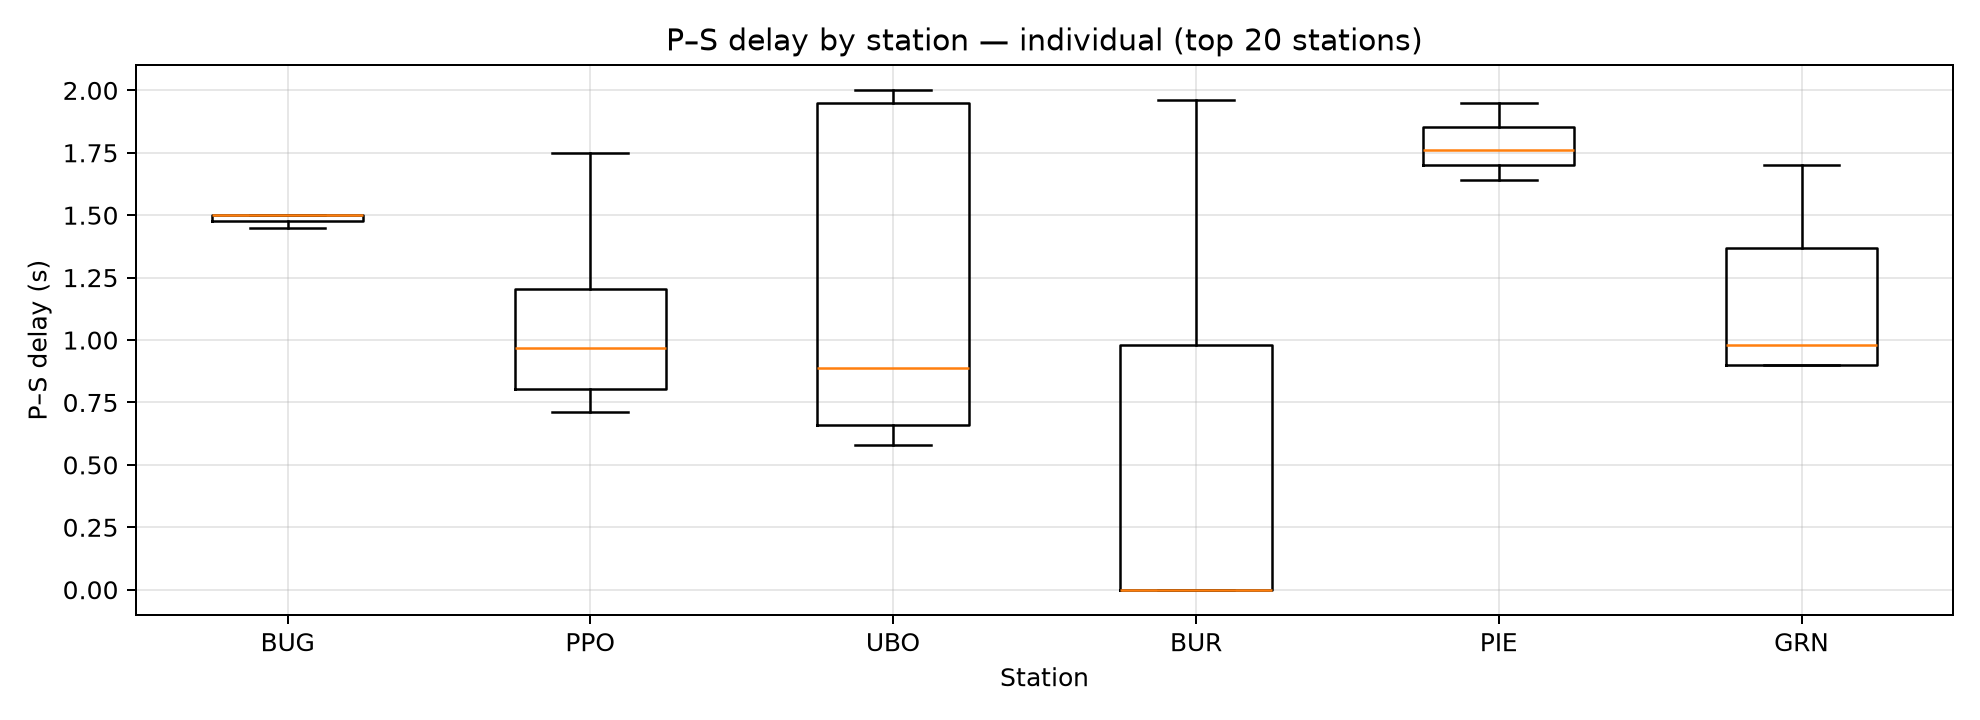

**Monthly-file P–S pairs:** station distributions from step-21 source blocks. See “Reading the P–S delay diagnostics” above for selection rules and limitations.

/Users/thompsong/work/Pinatubo1991Processing/converted/pipeline_tmp/qc/step23_pick_event_diagnostics/23_box_ps_delay_by_station_monthly.png


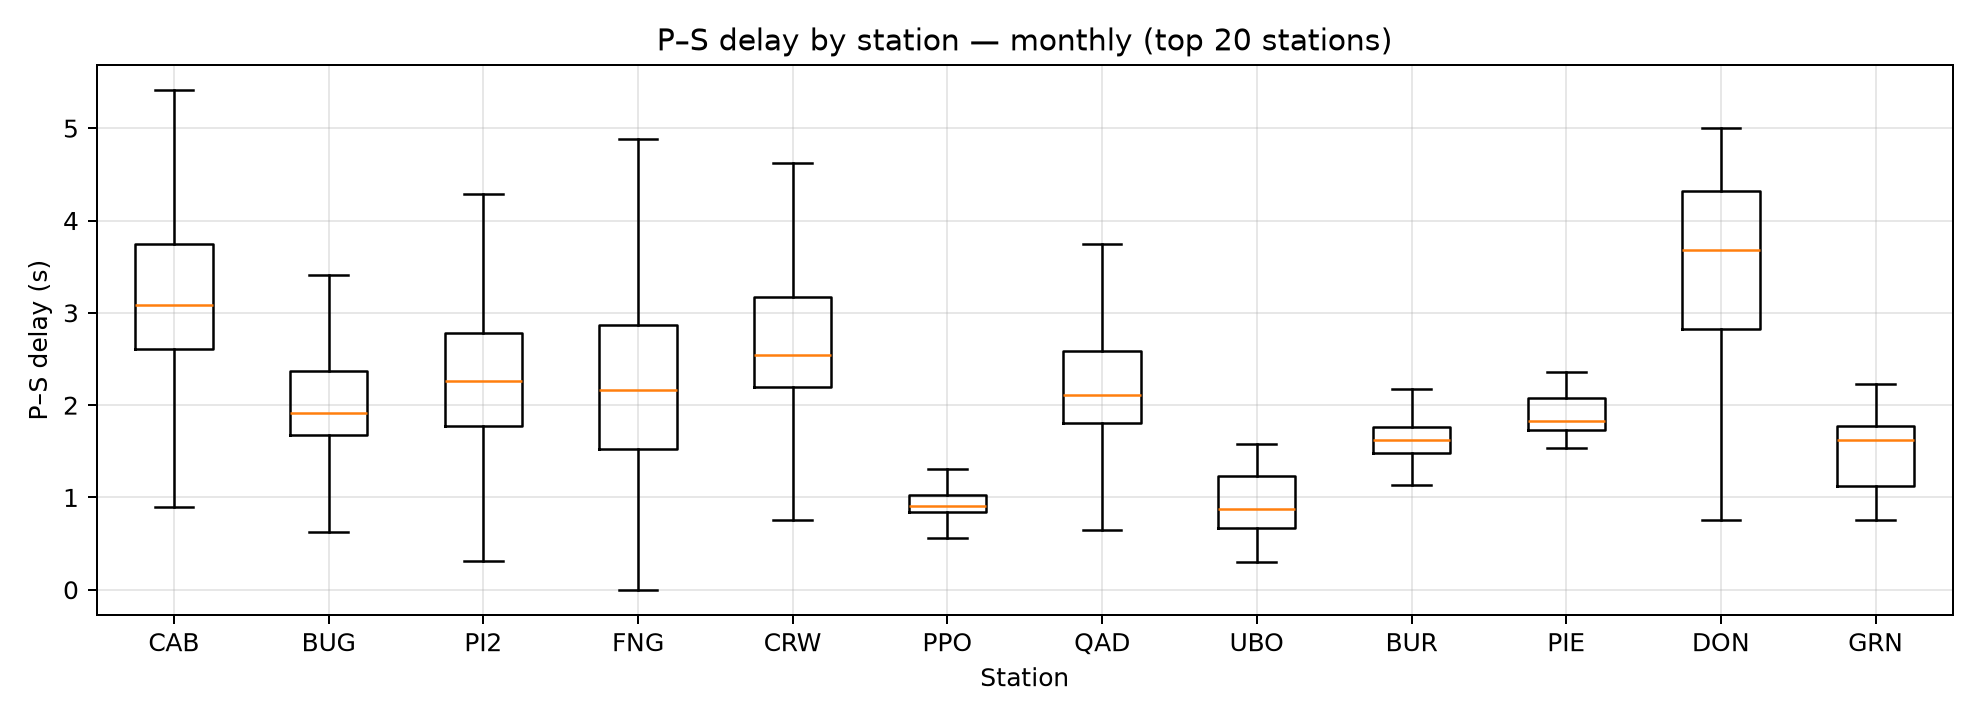

**Merged P–S pairs:** recalculated within surviving step-22 groups; overlaps the inputs. See “Reading the P–S delay diagnostics” above for selection rules and limitations.

/Users/thompsong/work/Pinatubo1991Processing/converted/pipeline_tmp/qc/step23_pick_event_diagnostics/23_box_ps_delay_by_station_merged.png


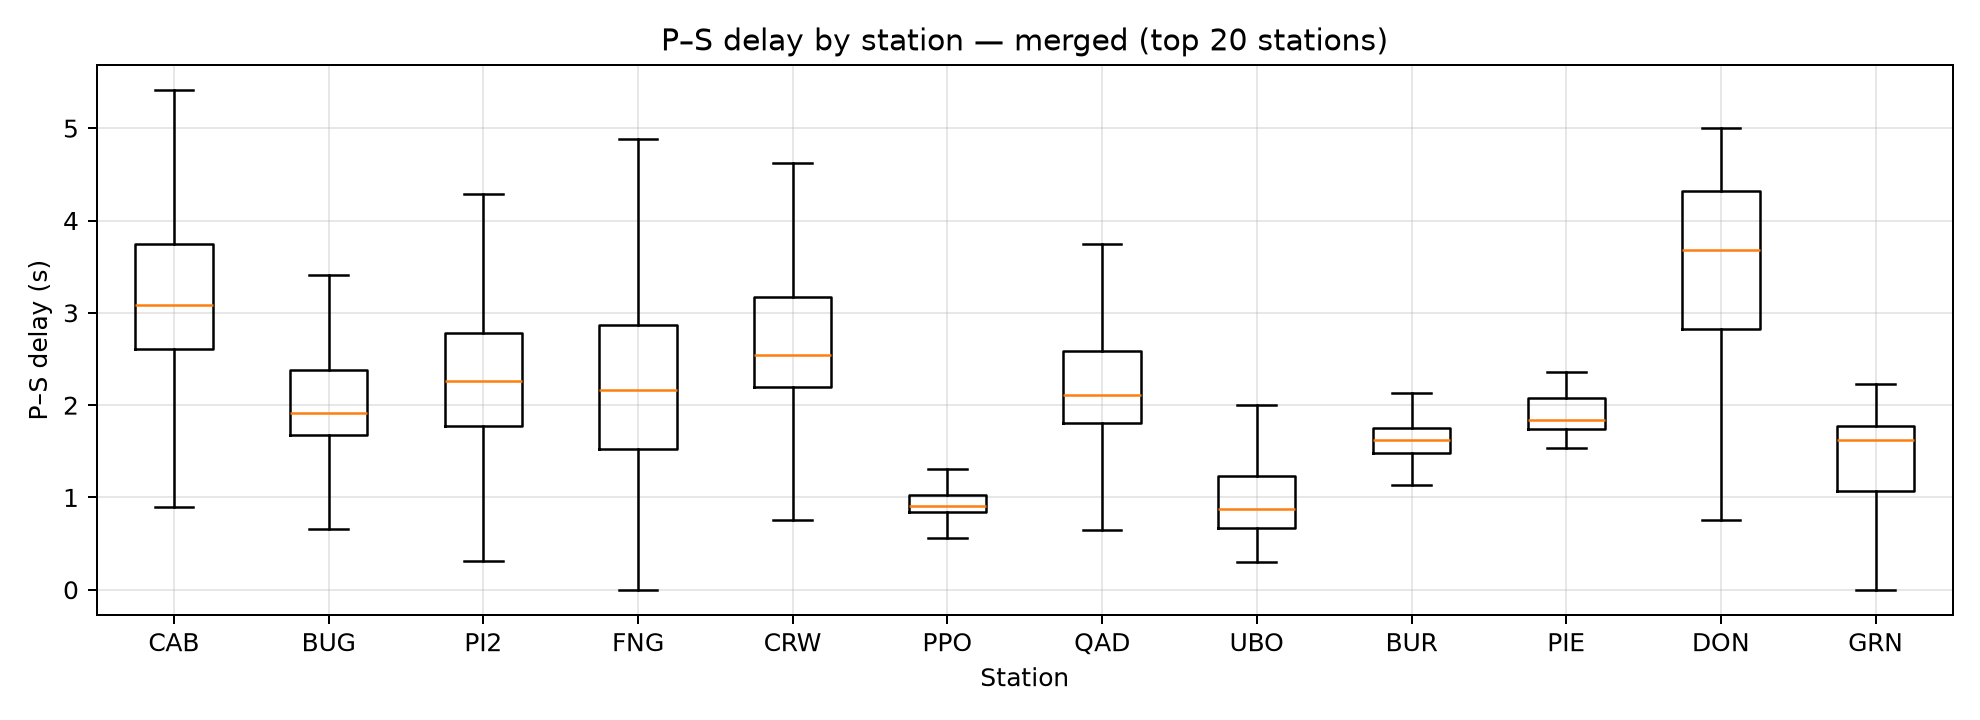

**P–S histogram:** pooled accepted pairs, overlaid by input table; populations overlap. See “Reading the P–S delay diagnostics” above for selection rules and limitations.

/Users/thompsong/work/Pinatubo1991Processing/converted/pipeline_tmp/qc/step23_pick_event_diagnostics/23_hist_ps_delay_s.png


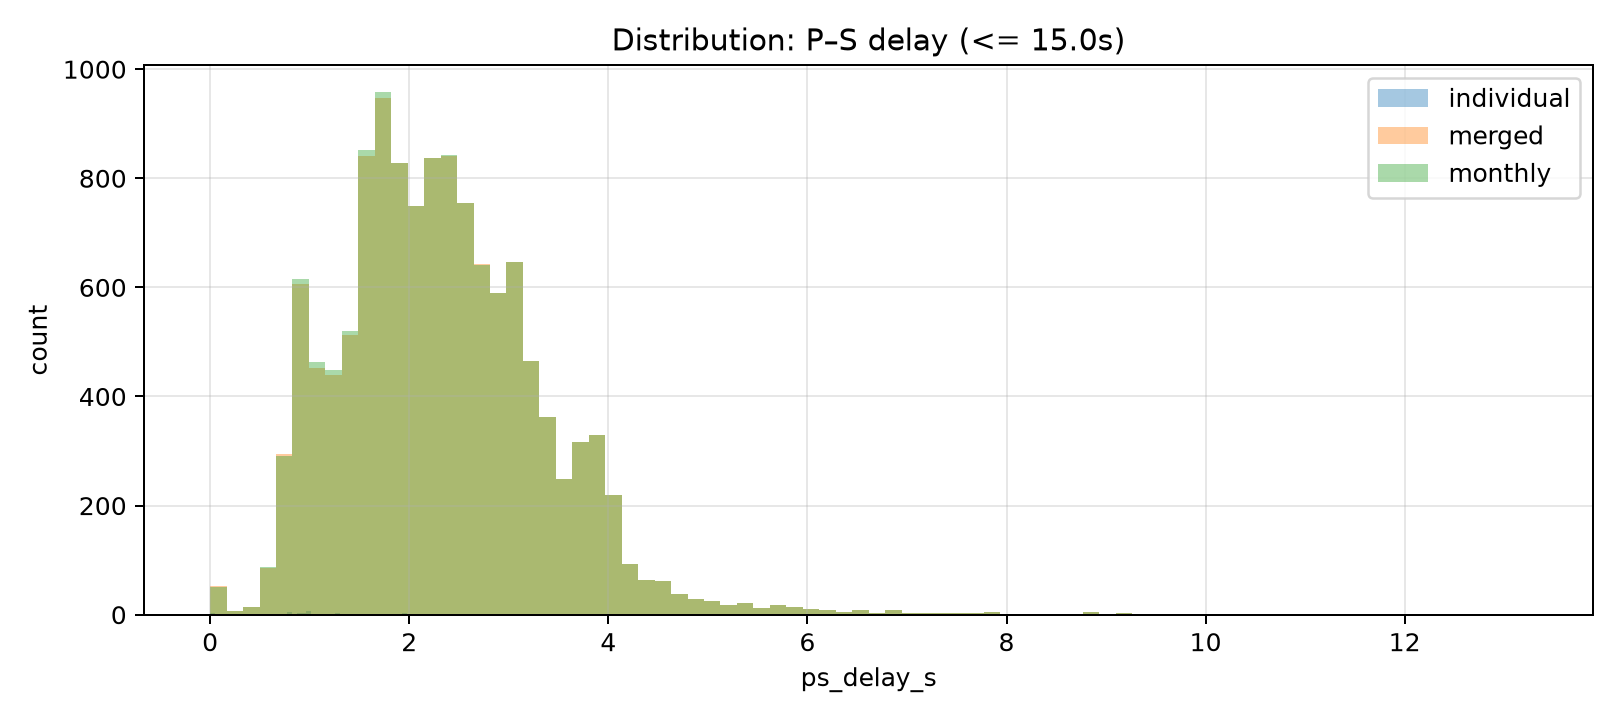

**events per day**

/Users/thompsong/work/Pinatubo1991Processing/converted/pipeline_tmp/qc/step23_pick_event_diagnostics/23_events_per_day.png


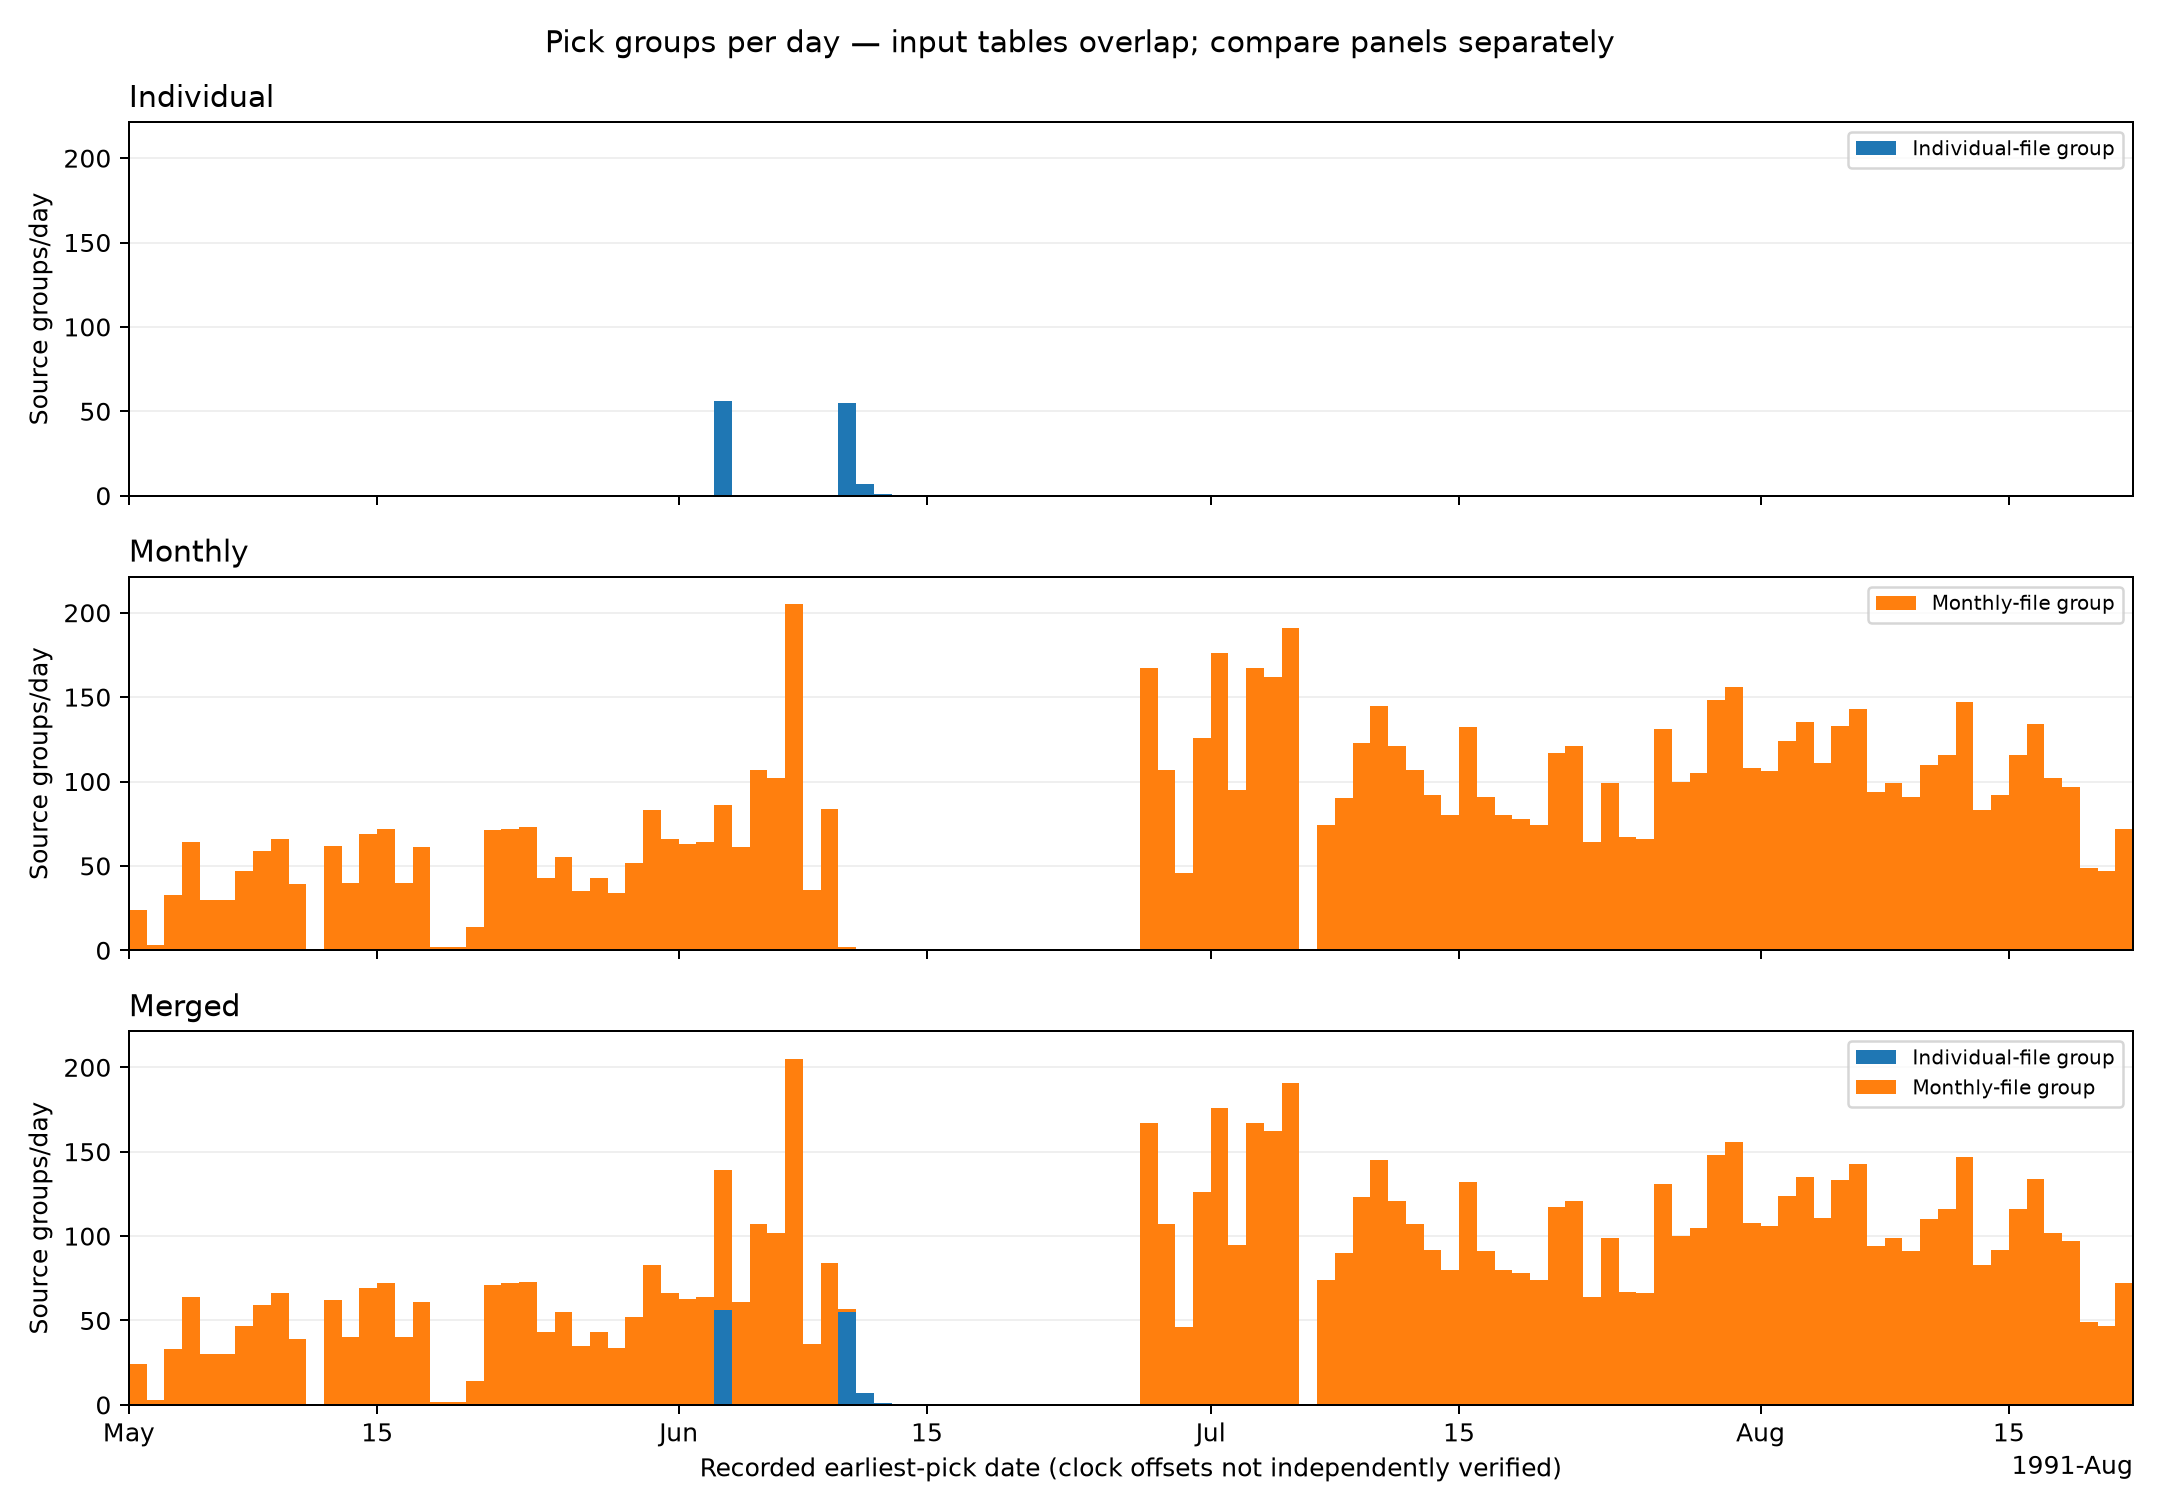

**hist event duration s**

/Users/thompsong/work/Pinatubo1991Processing/converted/pipeline_tmp/qc/step23_pick_event_diagnostics/23_hist_event_duration_s.png


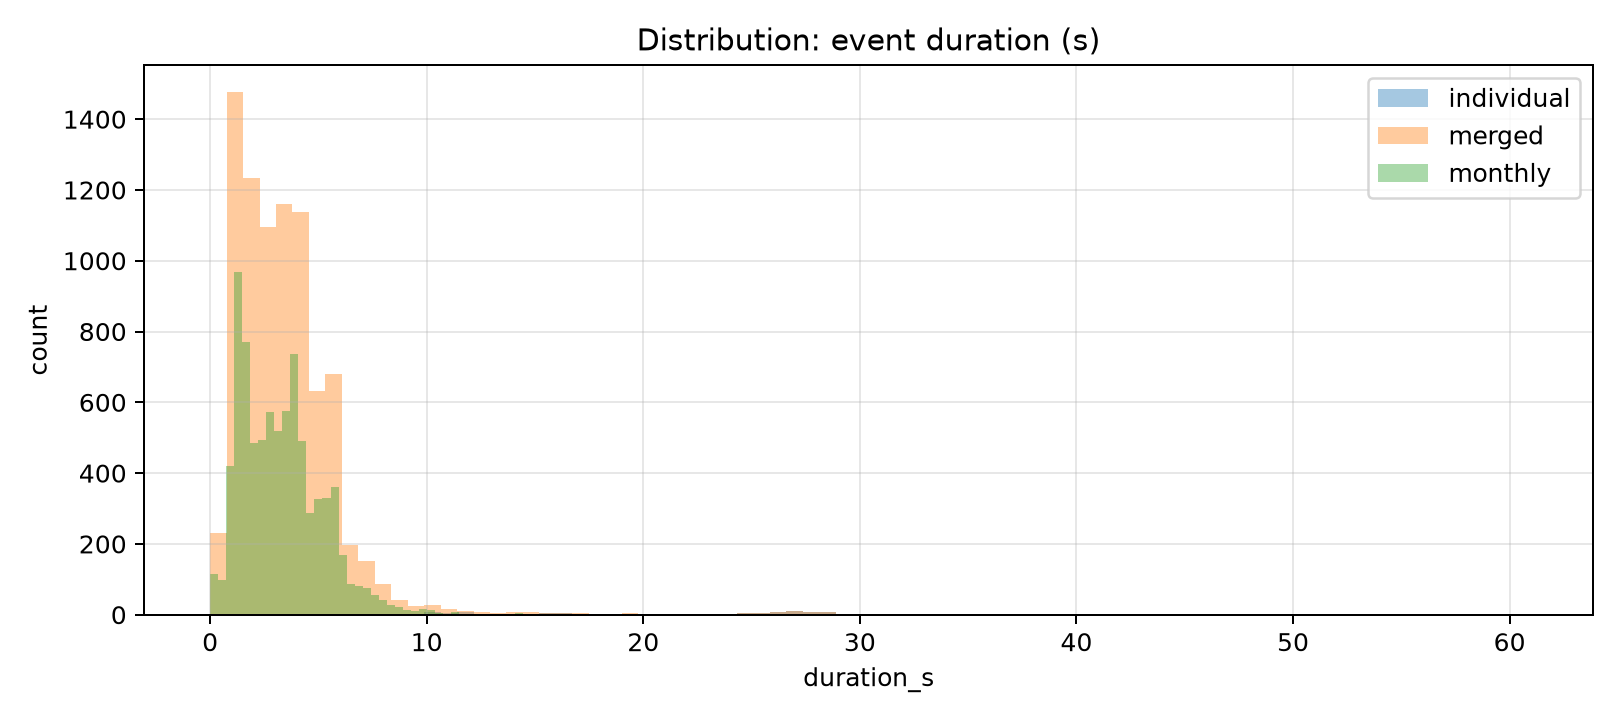

**hist picks per event**

/Users/thompsong/work/Pinatubo1991Processing/converted/pipeline_tmp/qc/step23_pick_event_diagnostics/23_hist_picks_per_event.png


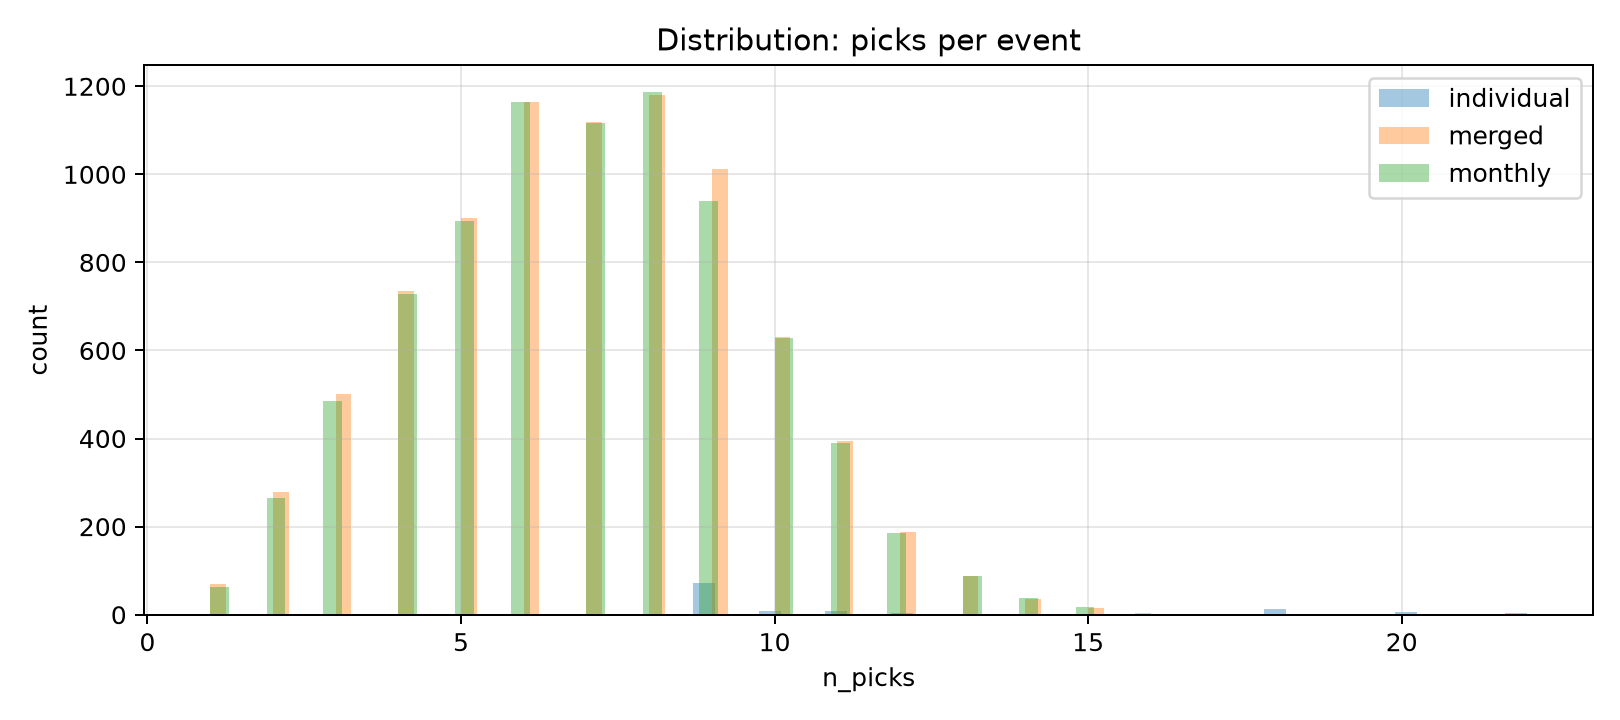

**median event duration per day**

/Users/thompsong/work/Pinatubo1991Processing/converted/pipeline_tmp/qc/step23_pick_event_diagnostics/23_median_event_duration_per_day.png


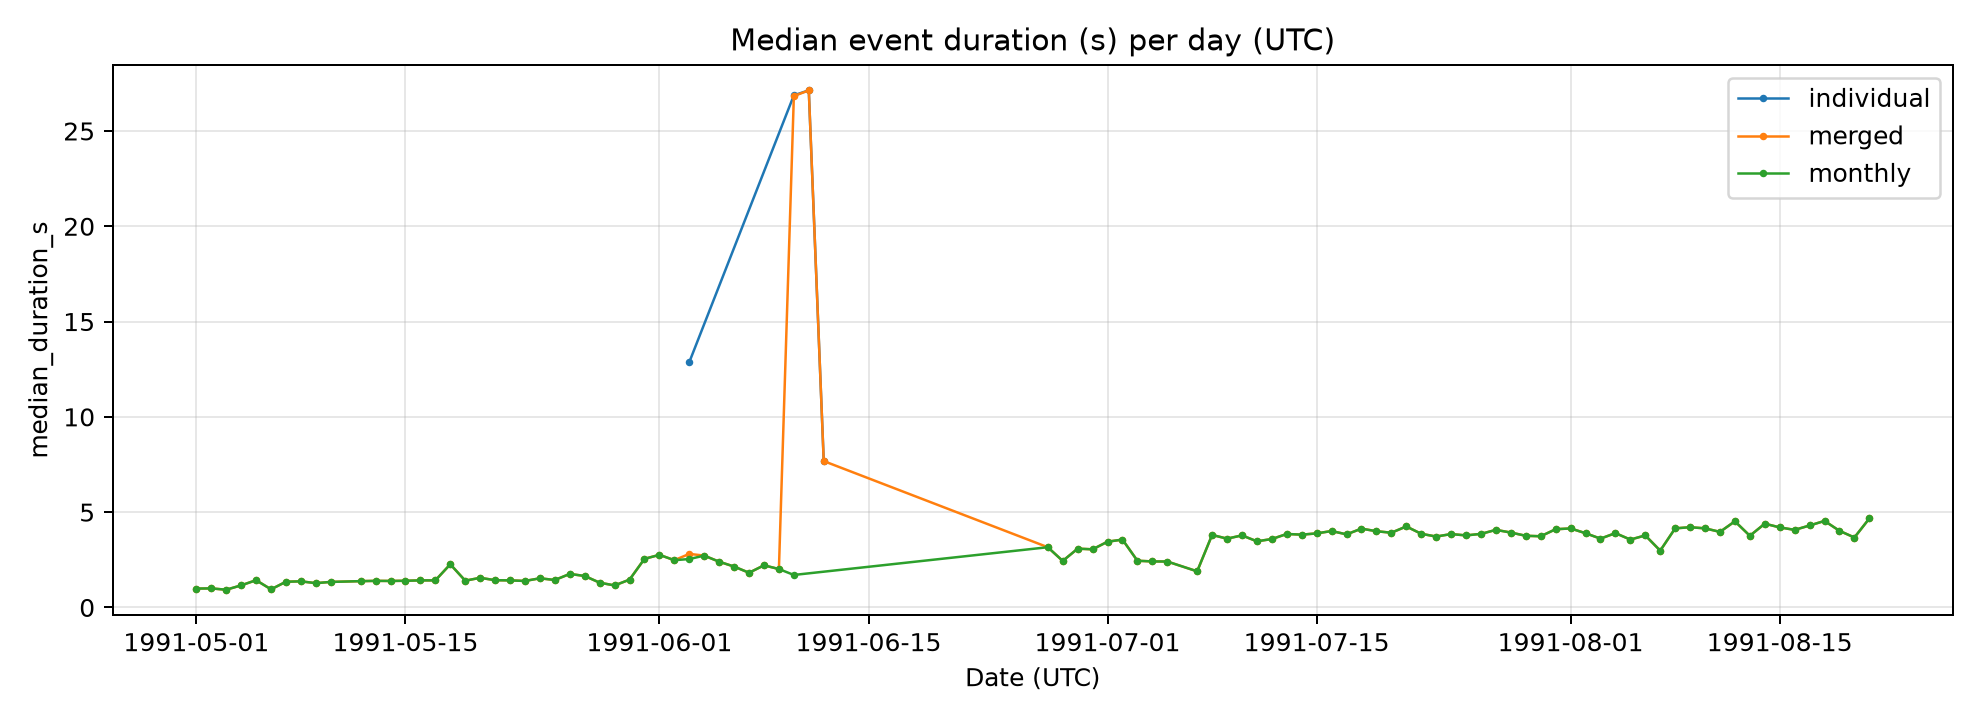

**median picks per event per day**

/Users/thompsong/work/Pinatubo1991Processing/converted/pipeline_tmp/qc/step23_pick_event_diagnostics/23_median_picks_per_event_per_day.png


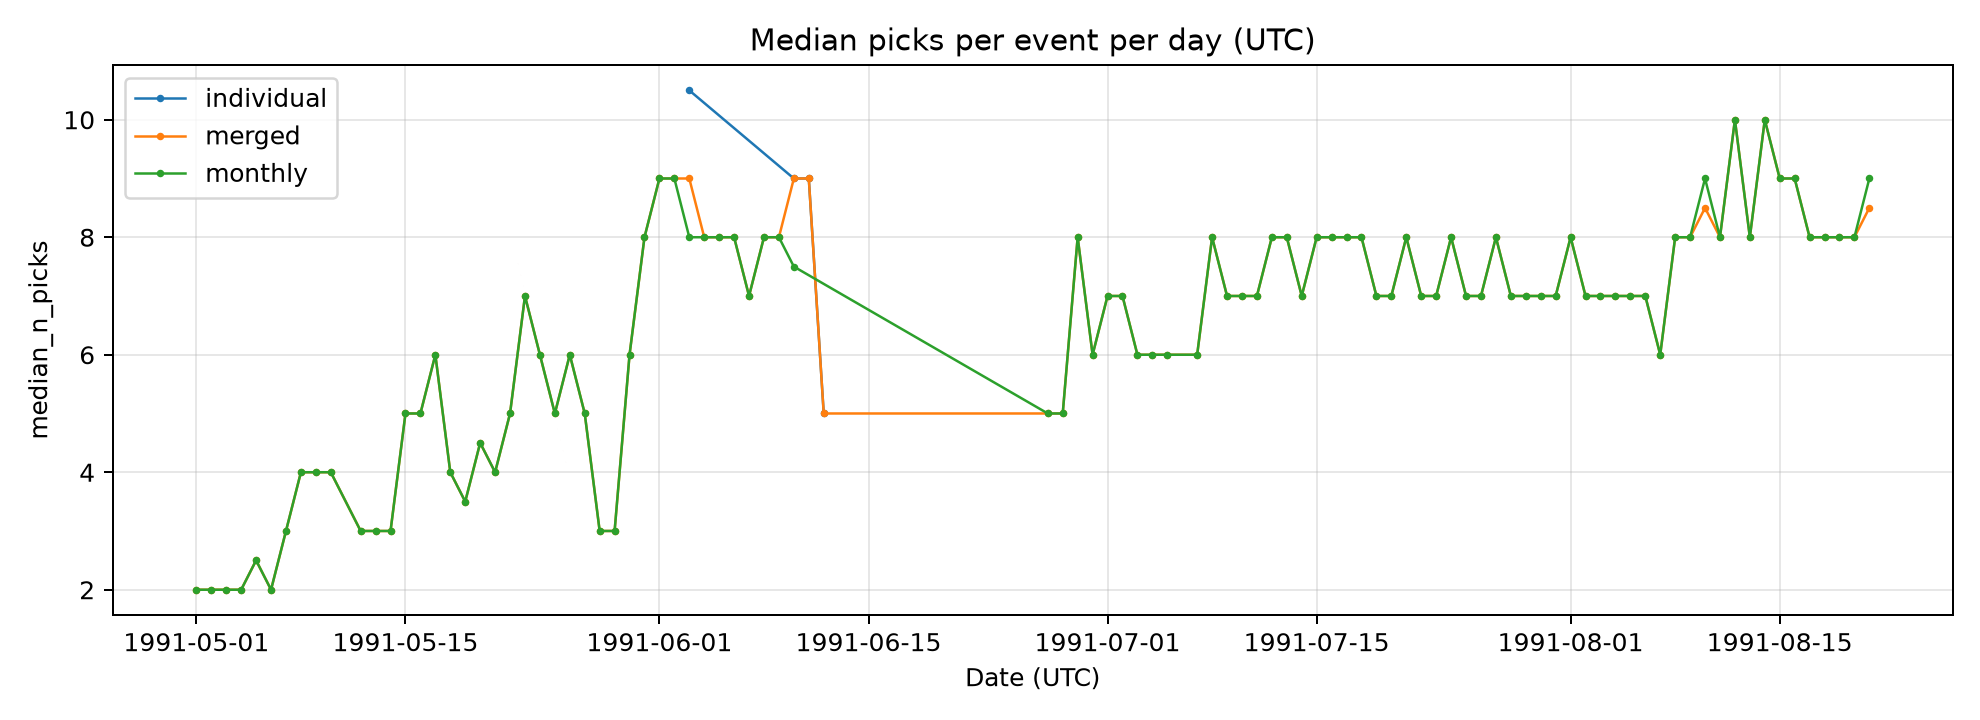

**phase fraction individual**

/Users/thompsong/work/Pinatubo1991Processing/converted/pipeline_tmp/qc/step23_pick_event_diagnostics/23_phase_fraction_individual.png


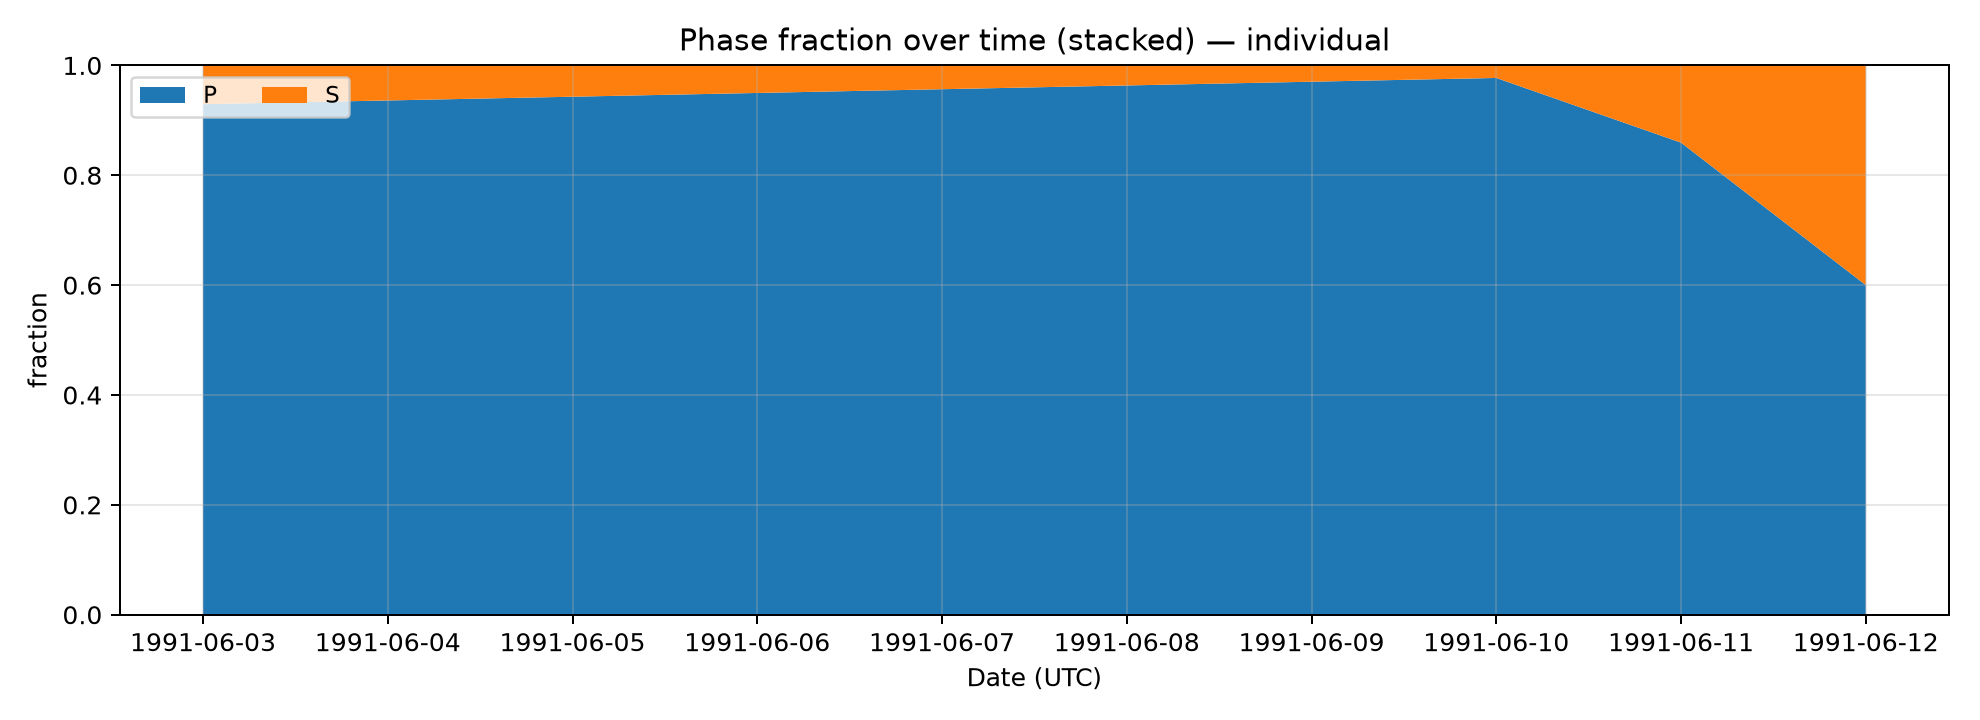

**phase fraction merged**

/Users/thompsong/work/Pinatubo1991Processing/converted/pipeline_tmp/qc/step23_pick_event_diagnostics/23_phase_fraction_merged.png


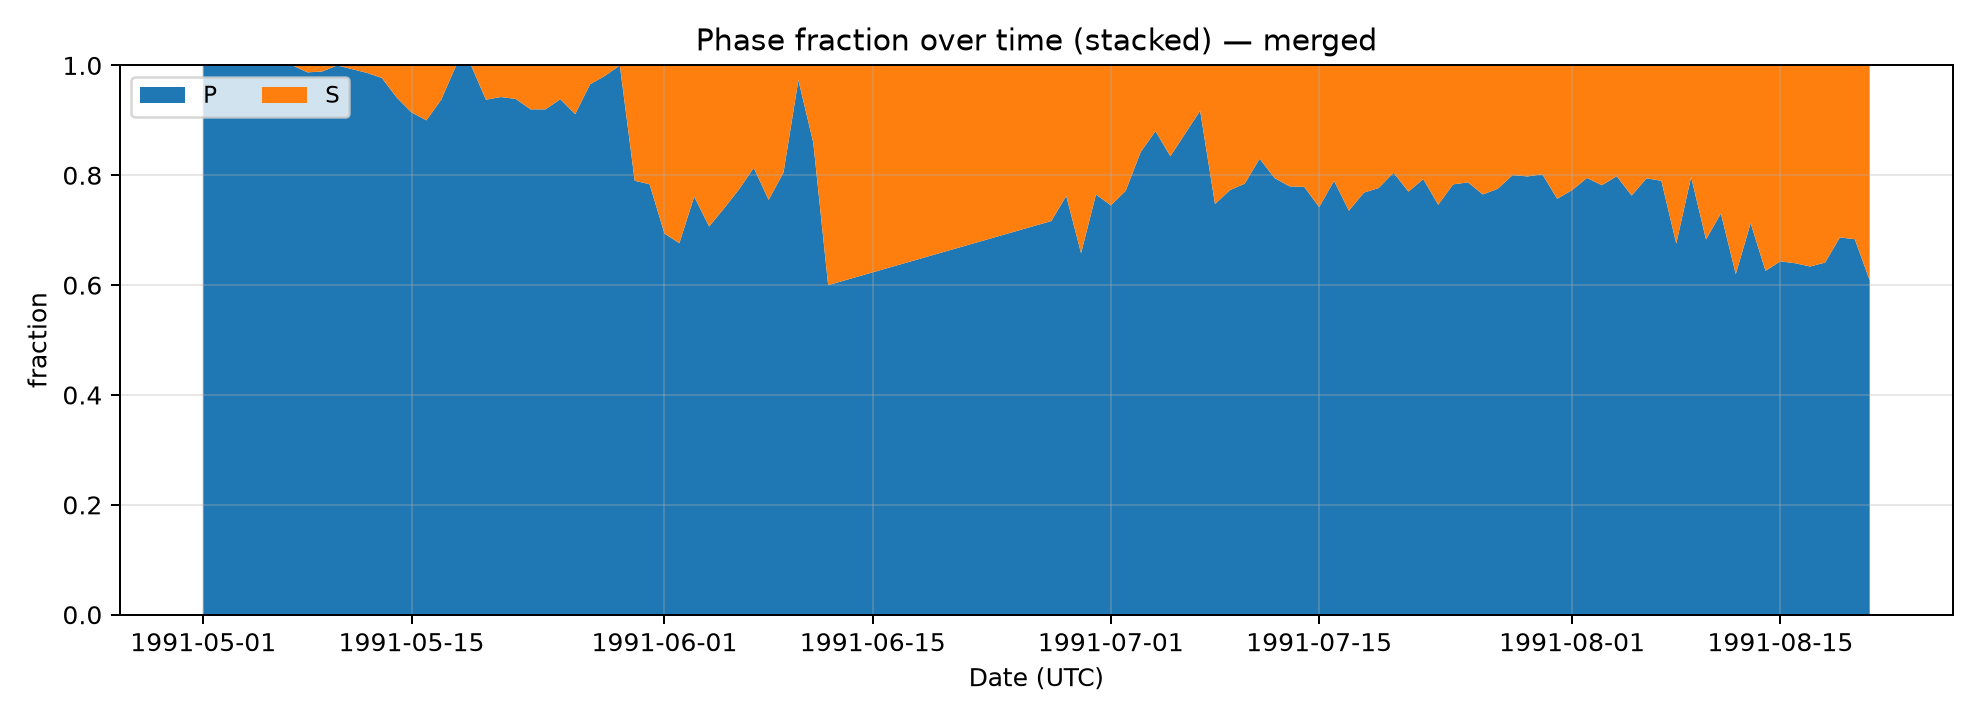

**phase fraction monthly**

/Users/thompsong/work/Pinatubo1991Processing/converted/pipeline_tmp/qc/step23_pick_event_diagnostics/23_phase_fraction_monthly.png


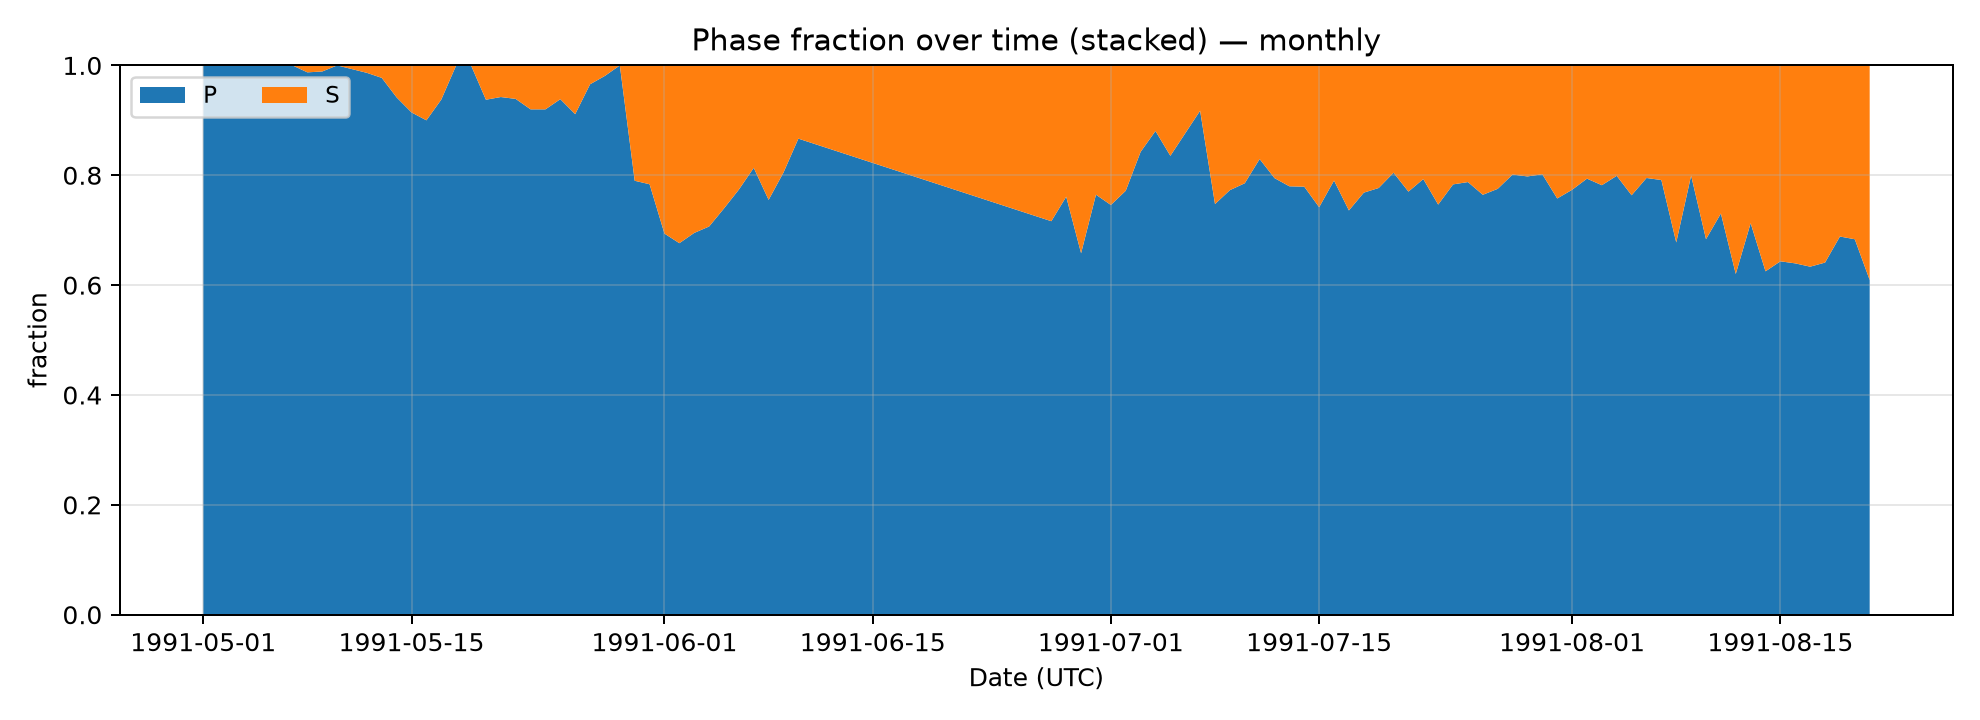

**picks per day**

/Users/thompsong/work/Pinatubo1991Processing/converted/pipeline_tmp/qc/step23_pick_event_diagnostics/23_picks_per_day.png


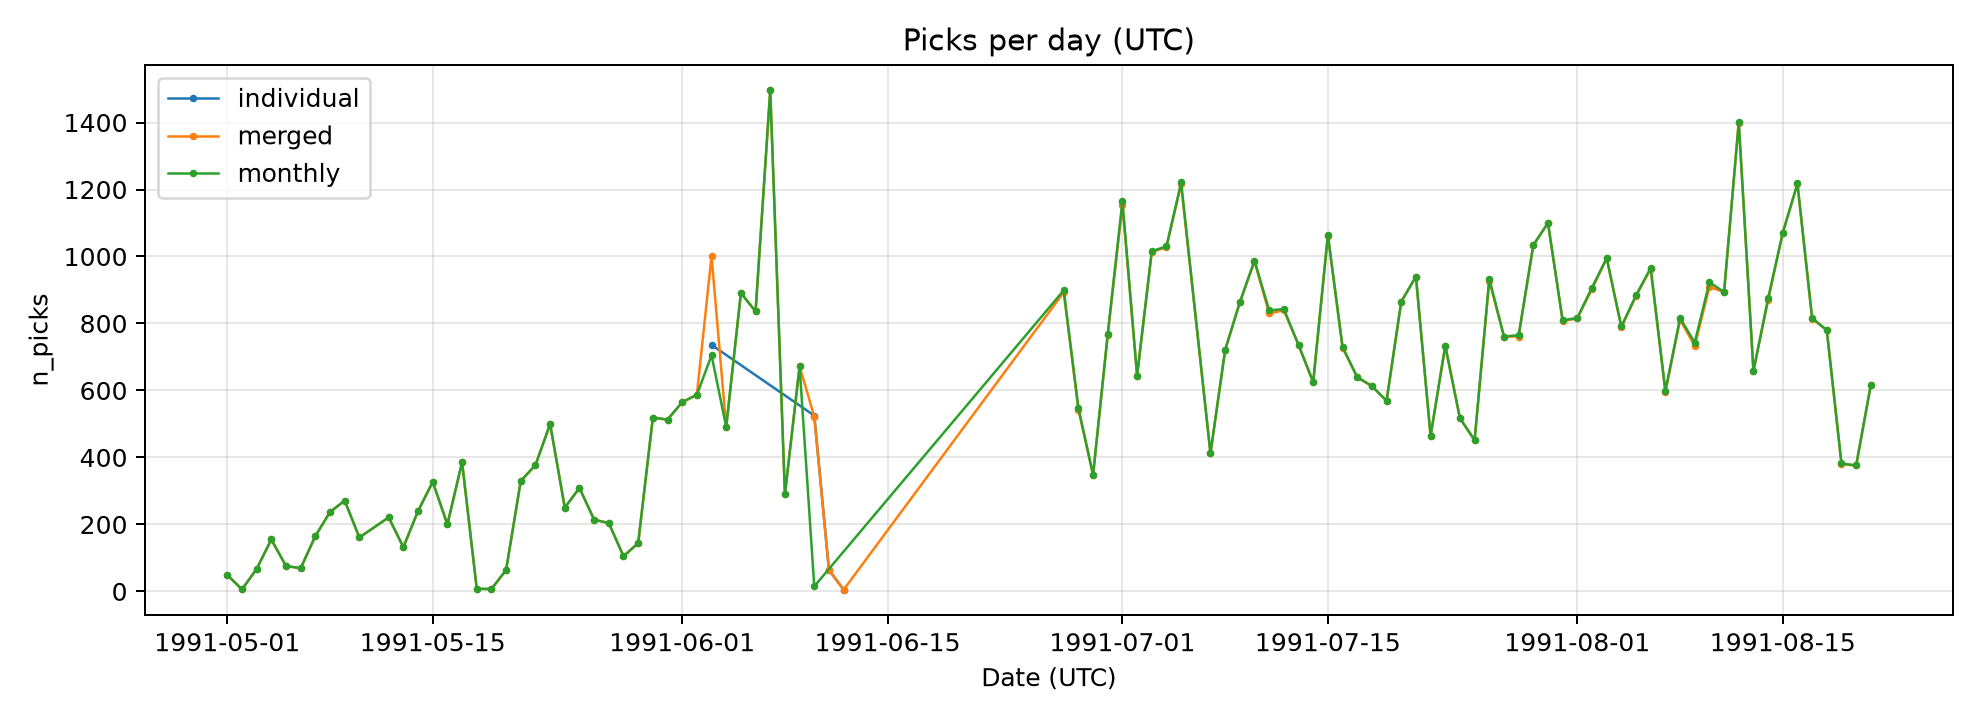

**station pick counts stacked individual**

/Users/thompsong/work/Pinatubo1991Processing/converted/pipeline_tmp/qc/step23_pick_event_diagnostics/23_station_pick_counts_stacked_individual.png


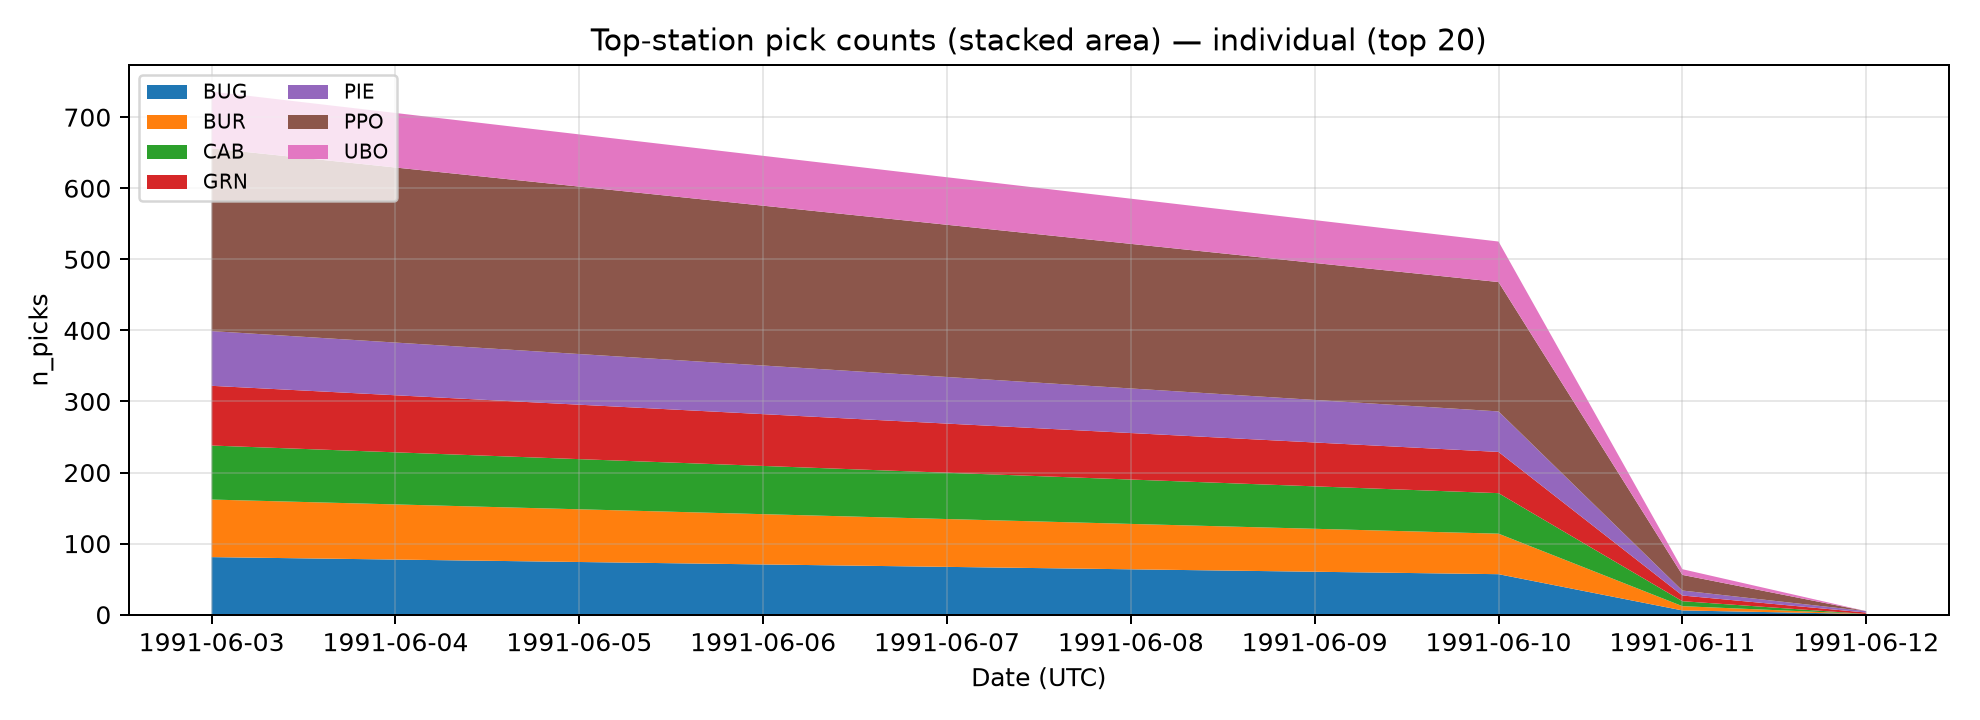

**station pick counts stacked merged**

/Users/thompsong/work/Pinatubo1991Processing/converted/pipeline_tmp/qc/step23_pick_event_diagnostics/23_station_pick_counts_stacked_merged.png


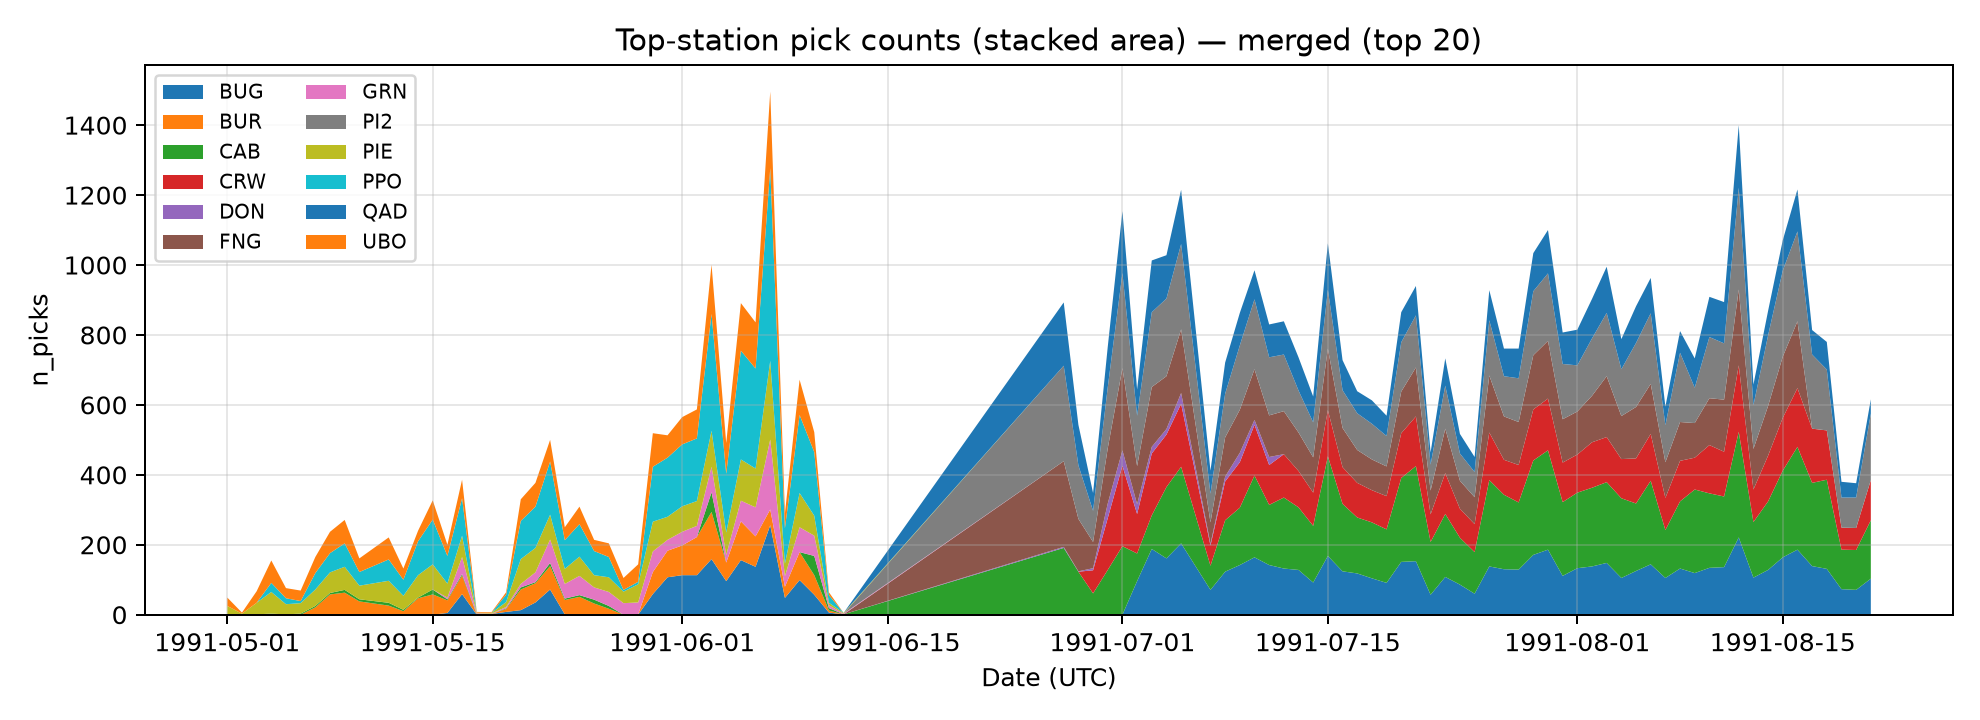

**station pick counts stacked monthly**

/Users/thompsong/work/Pinatubo1991Processing/converted/pipeline_tmp/qc/step23_pick_event_diagnostics/23_station_pick_counts_stacked_monthly.png


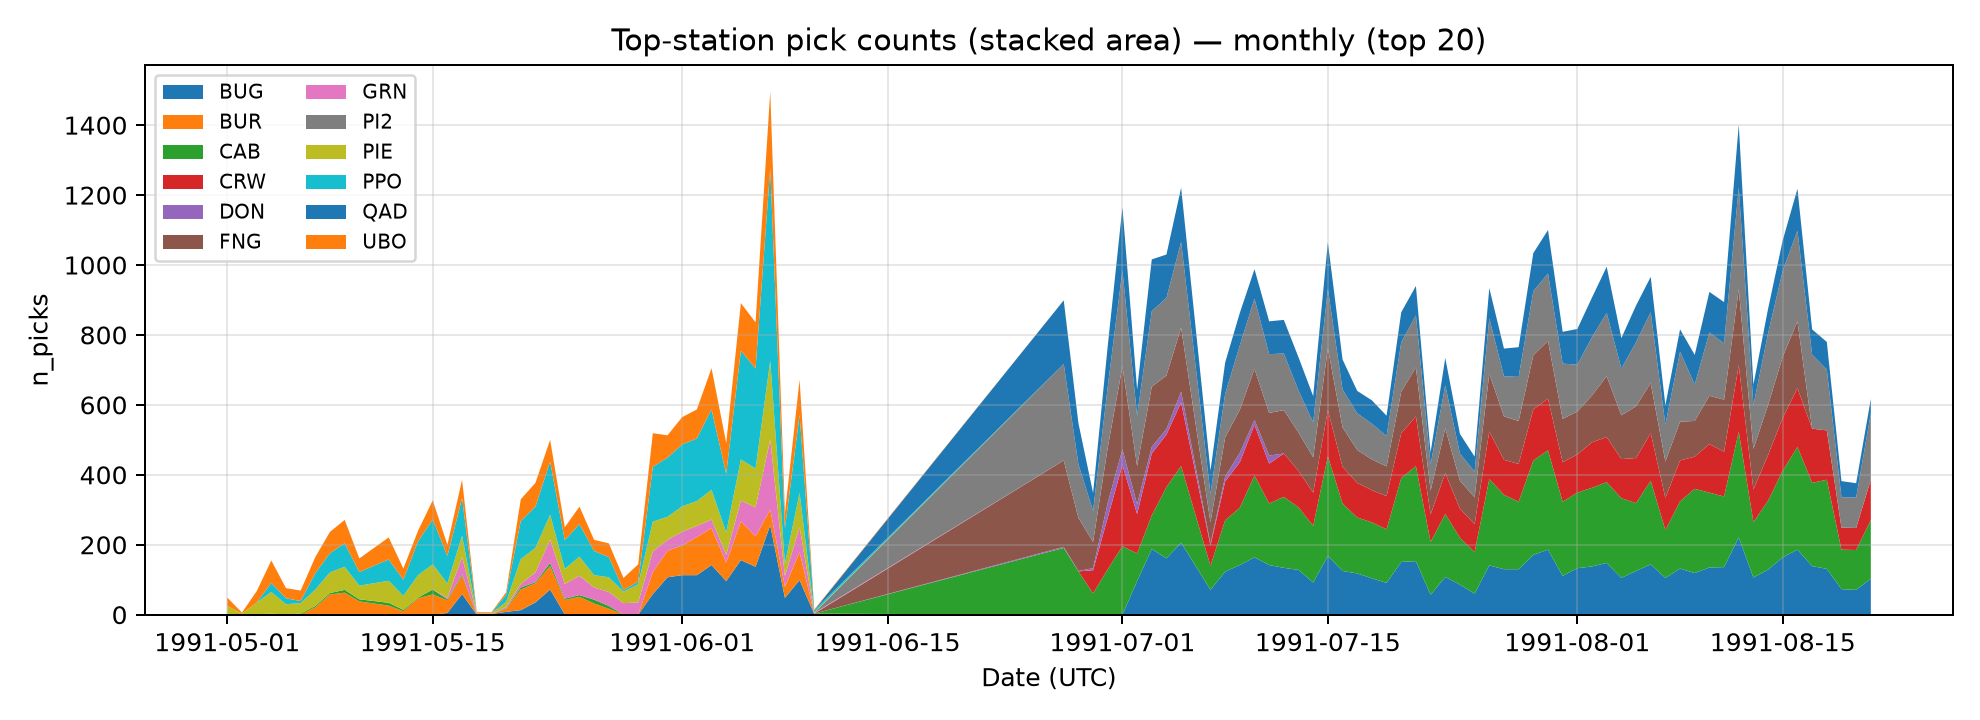

Saved files may include older runs. Check modification times if the current run skipped a product.


In [16]:
from IPython.display import Image, Markdown

# Display the P–S products together with captions, then the remaining diagnostics.
# This gallery reads saved PNGs only; it does not rerun calculations.
root = Path(SETTINGS['outdir'])
ps_captions = {
    '23_box_ps_delay_by_station_individual.png': '**Individual-file P–S pairs:** station distributions from step-20 source groups.',
    '23_box_ps_delay_by_station_monthly.png': '**Monthly-file P–S pairs:** station distributions from step-21 source blocks.',
    '23_box_ps_delay_by_station_merged.png': '**Merged P–S pairs:** recalculated within surviving step-22 groups; overlaps the inputs.',
    '23_hist_ps_delay_s.png': '**P–S histogram:** pooled accepted pairs, overlaid by input table; populations overlap.',
}
for name, caption in ps_captions.items():
    path = root / name
    display(Markdown(caption + ' See “Reading the P–S delay diagnostics” above for selection rules and limitations.'))
    if path.is_file():
        print(path)
        display(Image(filename=str(path)))
    else:
        print('No saved figure:', path.name, '(check whether pairs were available).')

SHOW_OTHER_PLOTS = True
if SHOW_OTHER_PLOTS:
    for path in sorted(root.glob('23_*.png')):
        if path.name not in ps_captions:
            display(Markdown('**' + path.stem.replace('23_', '', 1).replace('_', ' ') + '**'))
            print(path)
            display(Image(filename=str(path)))
print('Saved files may include older runs. Check modification times if the current run skipped a product.')


## Individual ↔ monthly PHA cross-check

This section can run independently after the common setup cell; it does not require step 22 or rerun either parser. It reads existing step-20/21 CSVs and writes separate reports. No picks are reassigned, suppressed or rewritten.

Match identity is the full normalized SEED ID and phase, including network, location, channel orientation and gain. Each tolerance is inclusive. Overlap means at least one counterpart exists, not one-to-one agreement. Mutual-unique pairs have exactly one candidate on both sides; multiple candidates and reused counterparts are reported explicitly. Signed offsets are monthly minus individual time.

Dates select UTC reporting days, while candidate matching retains neighboring-day context across midnight. Empty denominators produce NaN, not a zero success rate. Missing input files raise an error. Invalid records remain in their own audit table; rows with unknown times cannot be attributed to a selected day.

Date audits compare folder, filename and pick dates only where metadata permits. Future step-20 outputs include pha_path. Older CSVs containing only a basename cannot support a folder-date check; the report marks insufficient metadata rather than guessing. Source agreement alone does not prove parser correctness.


In [17]:
from pinatubo_steps.pha_comparison import compare_pick_csvs

COMPARISON_TOLERANCES = (0.05, 1.0)  # Seconds; reported separately.
COMPARISON_DATES = ['910603', '910610']  # Set None to report every pick date.
COMPARISON_OUTPUT = Path(SETTINGS['outdir']) / 'pha_cross_source'

comparison = compare_pick_csvs(
    SETTINGS['individual'], SETTINGS['monthly'],
    outdir=COMPARISON_OUTPUT,
    tolerances=COMPARISON_TOLERANCES,
    dates=COMPARISON_DATES,
)
print('Validation reports:', COMPARISON_OUTPUT)


Validation reports: /Users/thompsong/work/Pinatubo1991Processing/converted/pipeline_tmp/qc/step23_pick_event_diagnostics/pha_cross_source


In [18]:
display(comparison['summary'])
display(comparison['timing_summary'])
print('Invalid source records (all dates):', len(comparison['invalid']))
display(comparison['invalid'].head(20))
print('Date discrepancies:')
display(comparison['date_audit'].loc[comparison['date_audit']['date_mismatch']].head(30))
print('Ambiguous candidate pairs:')
display(comparison['ambiguous_pairs'].head(30))
print('Unmatched picks by tolerance:')
display(comparison['unmatched'].head(30))
unmatched_ids = set(comparison['unmatched']['comparison_row_id'])
print('Nearest same-identity candidates for unmatched rows (diagnostic only):')
display(comparison['nearest_candidates'].loc[
    comparison['nearest_candidates']['comparison_row_id'].isin(unmatched_ids)
].head(30))


,source,date,tolerance_s,total_picks,valid_picks,invalid_picks,matched,unmatched,mutual_unique,multiple_candidates,reused_counterpart,match_rate,coverage_status
0,individual,ALL,0.05,1261,1261,0,259,1002,125,0,134,0.205393,observed
1,individual,1991-06-03,0.05,736,736,0,259,477,125,0,134,0.351902,observed
2,individual,1991-06-10,0.05,525,525,0,0,525,0,0,0,0.000000,observed
3,monthly,ALL,0.05,720,720,0,192,528,125,67,0,0.266667,observed
4,monthly,1991-06-03,0.05,705,705,0,192,513,125,67,0,0.272340,observed
5,monthly,1991-06-10,0.05,15,15,0,0,15,0,0,0,0.000000,observed
6,individual,ALL,1.00,1261,1261,0,351,910,169,0,182,0.278351,observed
7,individual,1991-06-03,1.00,736,736,0,351,385,169,0,182,0.476902,observed
8,individual,1991-06-10,1.00,525,525,0,0,525,0,0,0,0.000000,observed
9,monthly,ALL,1.00,720,720,0,260,460,169,91,0,0.361111,observed


,tolerance_s,pair_set,pairs,median_delta_s,mean_delta_s,p95_abs_delta_s,max_abs_delta_s
0,0.05,all_candidates,259,0.0,-0.001042,0.040,0.05
1,0.05,mutual_unique,125,0.0,-0.000400,0.040,0.05
2,1.00,all_candidates,351,0.0,-0.006610,0.460,1.00
3,1.00,mutual_unique,169,0.0,-0.028047,0.556,1.00


Invalid source records (all dates): 0


,raw_line,raw_lineno,event_id,event_id_source,pick_id,pha_file,pha_path,station,channel,seed_id,...,weight,comparison_row_id,comparison_source,comparison_time,comparison_day,comparison_seed_id,comparison_phase,comparison_invalid_reason,comparison_valid,comparison_in_scope


Date discrepancies:


,comparison_row_id,source,pick_id,path,folder_day,filename_day,pick_day,date_mismatch,issues,audit_status,comparison_in_scope
1,individual:1,individual,indpha_91060300_562,/Users/thompsong/Library/CloudStorage/Box-Box/...,1991-06-10,1991-06-03,1991-06-03,True,folder_vs_filename;folder_vs_pick,mismatch,True
3,individual:3,individual,indpha_91060300_563,/Users/thompsong/Library/CloudStorage/Box-Box/...,1991-06-10,1991-06-03,1991-06-03,True,folder_vs_filename;folder_vs_pick,mismatch,True
5,individual:5,individual,indpha_91060300_564,/Users/thompsong/Library/CloudStorage/Box-Box/...,1991-06-10,1991-06-03,1991-06-03,True,folder_vs_filename;folder_vs_pick,mismatch,True
7,individual:7,individual,indpha_91060300_565,/Users/thompsong/Library/CloudStorage/Box-Box/...,1991-06-10,1991-06-03,1991-06-03,True,folder_vs_filename;folder_vs_pick,mismatch,True
9,individual:9,individual,indpha_91060300_566,/Users/thompsong/Library/CloudStorage/Box-Box/...,1991-06-10,1991-06-03,1991-06-03,True,folder_vs_filename;folder_vs_pick,mismatch,True
11,individual:11,individual,indpha_91060300_567,/Users/thompsong/Library/CloudStorage/Box-Box/...,1991-06-10,1991-06-03,1991-06-03,True,folder_vs_filename;folder_vs_pick,mismatch,True
13,individual:13,individual,indpha_91060300_571,/Users/thompsong/Library/CloudStorage/Box-Box/...,1991-06-10,1991-06-03,1991-06-03,True,folder_vs_filename;folder_vs_pick,mismatch,True
16,individual:16,individual,indpha_91060300_568,/Users/thompsong/Library/CloudStorage/Box-Box/...,1991-06-10,1991-06-03,1991-06-03,True,folder_vs_filename;folder_vs_pick,mismatch,True
17,individual:17,individual,indpha_91060300_569,/Users/thompsong/Library/CloudStorage/Box-Box/...,1991-06-10,1991-06-03,1991-06-03,True,folder_vs_filename;folder_vs_pick,mismatch,True
19,individual:19,individual,indpha_91060300_570,/Users/thompsong/Library/CloudStorage/Box-Box/...,1991-06-10,1991-06-03,1991-06-03,True,folder_vs_filename;folder_vs_pick,mismatch,True


... (2 outputs left out)

Unmatched picks by tolerance:


,raw_line,raw_lineno,event_id,event_id_source,pick_id,pha_file,pha_path,station,channel,seed_id,...,comparison_seed_id,comparison_phase,comparison_invalid_reason,comparison_valid,comparison_in_scope,comparison_tolerance_s,comparison_candidates,comparison_mutual_unique,comparison_reused_counterpart,comparison_status
2,BUGZ PU0 910603073938.49 39.99 S 2 ...,10,91060300,individual_pha_filename,indpha_91060300_2,91060300.PHA,/Users/thompsong/Library/CloudStorage/Box-Box/...,BUG,EHZ,XB.BUG..EHZ,...,XB.BUG..EHZ,S,,True,True,0.05,0,False,False,unmatched
3,BUGZ PU0 910603073938.49 39.99 S 2 ...,10,91060300,individual_pha_filename,indpha_91060300_563,91060300.PHA,/Users/thompsong/Library/CloudStorage/Box-Box/...,BUG,EHZ,XB.BUG..EHZ,...,XB.BUG..EHZ,S,,True,True,0.05,0,False,False,unmatched
6,CABZ P 5 910603073953.23,9,91060300,individual_pha_filename,indpha_91060300_4,91060300.PHA,/Users/thompsong/Library/CloudStorage/Box-Box/...,CAB,EHZ,XB.CAB..EHZ,...,XB.CAB..EHZ,P,,True,True,0.05,0,False,False,unmatched
7,CABZ P 5 910603073953.23,9,91060300,individual_pha_filename,indpha_91060300_565,91060300.PHA,/Users/thompsong/Library/CloudStorage/Box-Box/...,CAB,EHZ,XB.CAB..EHZ,...,XB.CAB..EHZ,P,,True,True,0.05,0,False,False,unmatched
8,GRNZ P 5 910603073953.23,2,91060300,individual_pha_filename,indpha_91060300_5,91060300.PHA,/Users/thompsong/Library/CloudStorage/Box-Box/...,GRN,EHZ,XB.GRN..EHZ,...,XB.GRN..EHZ,P,,True,True,0.05,0,False,False,unmatched
9,GRNZ P 5 910603073953.23,2,91060300,individual_pha_filename,indpha_91060300_566,91060300.PHA,/Users/thompsong/Library/CloudStorage/Box-Box/...,GRN,EHZ,XB.GRN..EHZ,...,XB.GRN..EHZ,P,,True,True,0.05,0,False,False,unmatched
14,PPOE P 3 910603073937.83,5,91060300,individual_pha_filename,indpha_91060300_7,91060300.PHA,/Users/thompsong/Library/CloudStorage/Box-Box/...,PPO,EHE,XB.PPO..EHE,...,XB.PPO..EHE,P,,True,True,0.05,0,False,False,unmatched
15,PPON P 3 910603073937.83 38.31 S 0,8,91060300,individual_pha_filename,indpha_91060300_8,91060300.PHA,/Users/thompsong/Library/CloudStorage/Box-Box/...,PPO,EHN,XB.PPO..EHN,...,XB.PPO..EHN,P,,True,True,0.05,0,False,False,unmatched
16,PPOE P 3 910603073937.83,5,91060300,individual_pha_filename,indpha_91060300_568,91060300.PHA,/Users/thompsong/Library/CloudStorage/Box-Box/...,PPO,EHE,XB.PPO..EHE,...,XB.PPO..EHE,P,,True,True,0.05,0,False,False,unmatched
17,PPON P 3 910603073937.83 38.31 S 0,8,91060300,individual_pha_filename,indpha_91060300_569,91060300.PHA,/Users/thompsong/Library/CloudStorage/Box-Box/...,PPO,EHN,XB.PPO..EHN,...,XB.PPO..EHN,P,,True,True,0.05,0,False,False,unmatched


Nearest same-identity candidates for unmatched rows (diagnostic only):


,source,comparison_row_id,counterpart_row_id,delta_s,abs_delta_s,reason,nearest_tie_count,pick_id,counterpart_pick_id,event_id,...,pha_file,counterpart_pha_file,pha_path,counterpart_pha_path,raw_line,counterpart_raw_line,raw_lineno,counterpart_raw_lineno,pick_time,counterpart_pick_time
4,individual,individual:44,monthly:42948,-251.59,251.59,outside_largest_tolerance,1,indpha_91060302_23,monpha_pinjun91_block0147_42949,91060302,...,91060302.PHA,pinjun91.pha,/Users/thompsong/Library/CloudStorage/Box-Box/...,NaN,BUGZ P 5 910603080958.81,BUGZEPD0 910603080547.22 48.88 S 4 ...,10,1057,1991-06-03T08:09:58.810000Z,1991-06-03T08:05:47.220000Z
5,individual,individual:45,monthly:42948,-251.59,251.59,outside_largest_tolerance,1,indpha_91060302_584,monpha_pinjun91_block0147_42949,91060302,...,91060302.PHA,pinjun91.pha,/Users/thompsong/Library/CloudStorage/Box-Box/...,NaN,BUGZ P 5 910603080958.81,BUGZEPD0 910603080547.22 48.88 S 4 ...,10,1057,1991-06-03T08:09:58.810000Z,1991-06-03T08:05:47.220000Z
6,individual,individual:62,monthly:42956,278.71,278.71,outside_largest_tolerance,1,indpha_91060303_32,monpha_pinjun91_block0148_42957,91060303,...,91060303.PHA,pinjun91.pha,/Users/thompsong/Library/CloudStorage/Box-Box/...,NaN,BUGZ P 5 910603082445.10,BUGZIPU0 910603082923.81 25.31 S 0 ...,10,1064,1991-06-03T08:24:45.100000Z,1991-06-03T08:29:23.810000Z
7,individual,individual:63,monthly:42956,278.71,278.71,outside_largest_tolerance,1,indpha_91060303_593,monpha_pinjun91_block0148_42957,91060303,...,91060303.PHA,pinjun91.pha,/Users/thompsong/Library/CloudStorage/Box-Box/...,NaN,BUGZ P 5 910603082445.10,BUGZIPU0 910603082923.81 25.31 S 0 ...,10,1064,1991-06-03T08:24:45.100000Z,1991-06-03T08:29:23.810000Z
8,individual,individual:80,monthly:42956,144.12,144.12,outside_largest_tolerance,1,indpha_91060304_41,monpha_pinjun91_block0148_42957,91060304,...,91060304.PHA,pinjun91.pha,/Users/thompsong/Library/CloudStorage/Box-Box/...,NaN,BUGZ P 5 910603082659.69,BUGZIPU0 910603082923.81 25.31 S 0 ...,10,1064,1991-06-03T08:26:59.690000Z,1991-06-03T08:29:23.810000Z
9,individual,individual:81,monthly:42956,144.12,144.12,outside_largest_tolerance,1,indpha_91060304_602,monpha_pinjun91_block0148_42957,91060304,...,91060304.PHA,pinjun91.pha,/Users/thompsong/Library/CloudStorage/Box-Box/...,NaN,BUGZ P 5 910603082659.69,BUGZIPU0 910603082923.81 25.31 S 0 ...,10,1064,1991-06-03T08:26:59.690000Z,1991-06-03T08:29:23.810000Z
12,individual,individual:120,monthly:42965,0.66,0.66,within_largest_tolerance,1,indpha_91060306_61,monpha_pinjun91_block0149_42966,91060306,...,91060306.PHA,pinjun91.pha,/Users/thompsong/Library/CloudStorage/Box-Box/...,NaN,BUGZ P 4 910603083016.18,BUGZEPD1 910603083016.84,10,1071,1991-06-03T08:30:16.180000Z,1991-06-03T08:30:16.840000Z
13,individual,individual:121,monthly:42965,0.66,0.66,within_largest_tolerance,1,indpha_91060306_622,monpha_pinjun91_block0149_42966,91060306,...,91060306.PHA,pinjun91.pha,/Users/thompsong/Library/CloudStorage/Box-Box/...,NaN,BUGZ P 4 910603083016.18,BUGZEPD1 910603083016.84,10,1071,1991-06-03T08:30:16.180000Z,1991-06-03T08:30:16.840000Z
26,individual,individual:247,monthly:43042,854.19,854.19,outside_largest_tolerance,1,indpha_9106030G_152,monpha_pinjun91_block0159_43043,9106030G,...,9106030G.PHA,pinjun91.pha,/Users/thompsong/Library/CloudStorage/Box-Box/...,NaN,BUGZ P 4 910603112539.72,BUGZIPU0 910603113953.91 55.48 S 0 ...,10,1134,1991-06-03T11:25:39.720000Z,1991-06-03T11:39:53.910000Z
32,individual,individual:302,monthly:43072,-1476.79,1476.79,outside_largest_tolerance,1,indpha_9106030M_207,monpha_pinjun91_block0163_43073,9106030M,...,9106030M.PHA,pinjun91.pha,/Users/thompsong/Library/CloudStorage/Box-Box/...,NaN,BUGZ P 3 910603125649.48,BUGZIPU0 910603123212.69 14.17 S 0 ...,10,1161,1991-06-03T12:56:49.480000Z,1991-06-03T12:32:12.690000Z
